# Лабораторная работа 2
Рекомендательная система для фильмов и сериалов KION

Трохан Александр Николаевич, M3415, ИСУ 334689.

## Рекомендации по своей истории
Для панели необходимо выполнить ячейки до данных. Загружается готовая
LambdaMART, выбранная по валидации. Если история пустая, используется MostPop.

В поиске нужно ввести часть названия и добавить несколько понравившихся фильмов.
После нажатия кнопки подбора появятся рекомендации.

`%pip install numpy pandas scipy matplotlib threadpoolctl ipywidgets scikit-learn lightgbm==4.6.0`.

In [4]:
from pathlib import Path
from zipfile import ZipFile
from urllib.request import urlopen
from time import perf_counter
import hashlib
import json
import shutil
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from threadpoolctl import threadpool_limits
from IPython.display import display, Markdown
from importlib.metadata import version

In [5]:
SEED = 42
TOP_K = 10
MAX_USERS = 30000
MAX_ITEMS = 3000
thread_limits = threadpool_limits(limits=1)
pd.set_option('display.max_colwidth', None)
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10})
ROOT = Path.cwd()
if (ROOT / 'АнДан' / 'Лабораторная 2').exists():
    ROOT = ROOT / 'АнДан' / 'Лабораторная 2'
DATA = ROOT / 'data'
WORK = ROOT / '.work'
FIGURES = WORK / 'figures'
DATA.mkdir(exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

In [6]:
environment_versions = {name: version(name) for name in [
    'numpy', 'pandas', 'scipy', 'matplotlib', 'threadpoolctl',
    'ipywidgets', 'scikit-learn', 'lightgbm']}
display(pd.Series(environment_versions, name='Версия').to_frame())

,Версия
numpy,2.3.3
pandas,3.0.0
scipy,1.17.0
matplotlib,3.10.8
threadpoolctl,3.6.0
ipywidgets,8.1.9
scikit-learn,1.8.0
lightgbm,4.6.0


In [7]:
RANKER_NAME = 'LambdaMART'
TIME_NAME = 'TimeEASE'
IMPROVED_NAME = 'TimeEASE-All'
TEMPORAL_NAMES = {TIME_NAME, IMPROVED_NAME}
EXPECTED_SHA256 = '50fc5b7db78cbda4c3d0ee5bb5bea4c416cff41e8af58aab0b661d0d3e9dfa9b'
DEMO_PATH = DATA / 'recommender_demo.npz'

In [8]:
from lightgbm import LGBMRanker

RANKER_FEATURE_NAMES = [
    'timeease_score', 'retrieval_rank', 'score_relative_max', 'log_pop7',
    'log_pop30', 'log_pop_all', 'trend7_vs30', 'positive_view_fraction',
    'mean_watch_pct', 'item_age_days', 'item_inactive_days', 'genre_affinity',
    'genre_time_affinity', 'user_positive_history', 'user_all_history',
    'user_time_history', 'user_recent7', 'score_x_genre', 'score_x_trend']
RANKER_FEATURE_LABELS = [
    'Оценка TimeEASE', 'Место в первой ступени', 'Оценка относительно максимума',
    'Популярность за 7 дней', 'Популярность за 30 дней', 'Популярность за все время',
    'Изменение популярности', 'Доля положительных просмотров', 'Средний процент просмотра',
    'Дней с первого наблюдения', 'Дней с последнего наблюдения', 'Совпадение жанров',
    'Совпадение жанров с учетом давности', 'Положительных фильмов в истории',
    'Всего фильмов в истории', 'Сумма временных весов истории', 'Просмотров за 7 дней',
    'Оценка с учетом жанров', 'Оценка с учетом тренда']
RANKER_FEATURE_VERSION = 'base_v1_19'

In [9]:
def save_demo_model(path):
    model = models[RANKER_NAME]
    context = model['context']
    manifest = {'format': 1, 'dataset_sha256': EXPECTED_SHA256,
                'feature_names': RANKER_FEATURE_NAMES, 'cutoff': '2021-08-16'}
    fields = ['title', 'content_type', 'release_year', 'genres']
    contents = {
        'manifest': np.array(json.dumps(manifest, ensure_ascii=False)),
        'catalog': np.asarray(catalog, dtype=np.int64),
        'metadata': np.array(metadata.loc[catalog, fields].reset_index().to_json(
            orient='records', force_ascii=False)),
        'genres': np.array(json.dumps([sorted(values) for values in genre_sets], ensure_ascii=False)),
        'popularity': np.asarray(models['MostPop']), 'weights': context['weights'],
        'genre_matrix': context['genre_matrix'], 'genre_counts': context['genre_counts'],
        'booster': np.array(model['booster'].model_to_string())}
    contents.update({f'stat_{name}': values for name, values in context['statistics'].items()})
    temporary = path.with_suffix('.tmp.npz')
    np.savez_compressed(temporary, **contents)
    temporary.replace(path)

In [10]:
from lightgbm import Booster

def load_demo_model(path):
    with np.load(path, allow_pickle=False) as saved:
        manifest = json.loads(saved['manifest'].item())
        assert manifest['format'] == 1 and manifest['cutoff'] == '2021-08-16'
        assert manifest['dataset_sha256'] == EXPECTED_SHA256
        assert manifest['feature_names'] == RANKER_FEATURE_NAMES
        selected_catalog = saved['catalog'].copy()
        selected_metadata = pd.DataFrame(json.loads(saved['metadata'].item())).set_index('item_id')
        selected_genres = [set(values) for values in json.loads(saved['genres'].item())]
        context = {name: saved[name].copy() for name in ['weights', 'genre_matrix', 'genre_counts']}
        context['statistics'] = {name[5:]: saved[name].copy() for name in saved.files if name.startswith('stat_')}
        assert context['weights'].shape == (len(selected_catalog), len(selected_catalog))
        assert len(selected_genres) == len(selected_catalog)
        booster = Booster(params={'num_threads': 1}, model_str=saved['booster'].item())
        selected_models = {'MostPop': saved['popularity'].copy(),
                           RANKER_NAME: {'booster': booster, 'context': context}}
    return selected_catalog, selected_metadata, selected_genres, selected_models

In [11]:
demo_ready = False
models = {}
best_model = RANKER_NAME
if DEMO_PATH.exists():
    try:
        catalog, metadata, genre_sets, models = load_demo_model(DEMO_PATH)
        item_index = pd.Index(catalog)
        demo_ready = True
        print('Model ready')
    except (OSError, ValueError, KeyError, AssertionError):
        print('Can not read model')
else:
    print('Execution started')
demo_ids = [item_id for item_id in [10440, 9728, 12920]
            if demo_ready and item_id in item_index]

Model ready


In [12]:
def stored_ranker_profile(context, user_row):
    return {'binary': context['binary'][user_row], 'time': context['time'][user_row],
        'seen': context['seen'][user_row],
        'genre': context['genre_profile'][user_row],
        'time_genre': context['time_genre_profile'][user_row],
        'counts': [context['counts'][user_row], context['seen_counts'][user_row],
                   context['time_counts'][user_row], context['recent_counts'][user_row]]}


def new_ranker_profile(context, watched_item_ids):
    columns = item_index.get_indexer(list(dict.fromkeys(watched_item_ids)))
    columns = columns[columns >= 0]
    if not len(columns):
        raise ValueError('At least 1 movie is required')
    history = sparse.csr_matrix((np.ones(len(columns), dtype=np.float32),
        (np.zeros(len(columns), dtype=int), columns)), shape=(1, len(catalog)))
    genres = np.asarray(history @ context['genre_matrix']).ravel() / len(columns)
    return {'binary': history, 'time': history, 'seen': history,
        'genre': genres, 'time_genre': genres,
        'counts': [len(columns)] * 4,
        'assumption': 'Даты неизвестны: все веса равны 1'}

In [13]:
def ranker_feature_rows(context, profile, columns, scores, global_top):
    stats = context['statistics']
    rank = np.full(len(catalog), 201, dtype=np.float32)
    rank[global_top] = np.arange(1, len(global_top) + 1)
    selected = scores[columns]
    genre = (profile['genre'] * context['genre_matrix'][columns]).sum(axis=1) / context['genre_counts'][columns]
    time_genre = (profile['time_genre'] * context['genre_matrix'][columns]).sum(axis=1) / context['genre_counts'][columns]
    trend = np.log1p(stats['pop7'][columns]) - np.log1p(stats['pop30'][columns] / 4)
    values = [selected, rank[columns], selected / max(float(scores[global_top[0]]), 1e-8),
        np.log1p(stats['pop7'][columns]), np.log1p(stats['pop30'][columns]),
        np.log1p(stats['pop'][columns]), trend,
        stats['pop'][columns] / np.maximum(stats['views'][columns], 1),
        stats['mean_pct'][columns], stats['age'][columns], stats['freshness'][columns],
        genre, time_genre, *[np.full(len(columns), value) for value in profile['counts']],
        selected * time_genre, selected * trend]
    return np.column_stack(values).astype(np.float32)

In [14]:
def ranker_profile_candidates(context, profile, allowed_candidates=None, scores=None):
    scores = np.asarray(profile['time'] @ context['weights']).ravel() if scores is None else scores.copy()
    scores[profile['seen'].indices] = -np.inf
    scores[context['statistics']['views'] == 0] = -np.inf
    order = np.argsort(-scores, kind='stable')
    global_top = order[:200]
    recent_order = np.argsort(-context['statistics']['pop7'], kind='stable')
    candidate_top, candidate_recent = global_top, recent_order[:50]
    if allowed_candidates is not None:
        allowed = np.asarray(allowed_candidates)
        if allowed.dtype != bool:
            allowed_columns = item_index.get_indexer(allowed)
            allowed = np.zeros(len(catalog), dtype=bool)
            allowed[allowed_columns[allowed_columns >= 0]] = True
        candidate_top = order[allowed[order]][:200]
        candidate_recent = recent_order[allowed[recent_order]][:50]
    columns = np.array(list(dict.fromkeys(np.r_[candidate_top, candidate_recent])), dtype=int)
    columns = columns[np.isfinite(scores[columns])]
    features = ranker_feature_rows(context, profile, columns, scores, global_top)
    return columns, features


def score_ranker_profile(model, profile, top_n=10, allowed_candidates=None):
    columns, features = ranker_profile_candidates(model['context'], profile, allowed_candidates)
    if not len(columns):
        return columns, features, np.array([])
    scores = model['booster'].predict(features)
    order = np.argsort(-scores, kind='stable')[:top_n]
    return columns[order], features[order], scores[order]


def ranker_shap_terms(model, features):
    terms = model['booster'].predict(features, pred_contrib=True)
    raw_scores = model['booster'].predict(features, raw_score=True)
    assert np.allclose(terms.sum(axis=1), raw_scores, atol=1e-9)
    return terms, raw_scores

In [15]:
def profile_vector(item_ids):
    unique_ids = list(dict.fromkeys(int(item_id) for item_id in item_ids))
    columns = item_index.get_indexer(unique_ids)
    unknown = [item_id for item_id, column in zip(unique_ids, columns) if column < 0]
    if unknown:
        raise ValueError(f'Объекты вне модельного каталога: {unknown}')
    values = np.ones(len(columns), dtype=np.float64)
    return sparse.csr_matrix((values, (np.zeros(len(columns), dtype=int), columns)),
                             shape=(1, len(catalog)))

def fold_in(profile, model):
    factors = model['item_factors']
    history = profile.indices
    weights = profile.data
    observed = factors[history]
    system = (factors.T @ factors + model['regularization'] * np.eye(model['factors']) +
              model['alpha'] * (observed.T @ (weights[:, None] * observed)))
    target = ((1 + model['alpha'] * weights)[:, None] * observed).sum(axis=0)
    return np.linalg.solve(system, target), system

In [16]:
def profile_scores(profile, model_name):
    if model_name == 'MostPop':
        return models['MostPop'].astype(float).copy()
    if model_name == 'ALS':
        factor, _ = fold_in(profile, models['ALS'])
        return factor @ models['ALS']['item_factors'].T
    if model_name in TEMPORAL_NAMES:
        model = models[model_name]
        return np.asarray(profile @ model['weights']).ravel()
    scores = profile @ models[model_name]
    return scores.toarray().ravel() if sparse.issparse(scores) else np.asarray(scores).ravel()

def profile_terms(profile, model_name, item_column):
    history, input_weights = profile.indices, profile.data
    if model_name == 'ALS':
        model = models['ALS']
        _, system = fold_in(profile, model)
        direction = np.linalg.solve(system, model['item_factors'][item_column])
        coefficients = model['item_factors'][history] @ direction
        values = (1 + model['alpha'] * input_weights) * coefficients
        return history, input_weights, values, 0.
    if model_name in TEMPORAL_NAMES:
        coefficients = models[model_name]['weights'][history, item_column]
    elif model_name == 'ItemKNN':
        coefficients = models[model_name][history, item_column].toarray().ravel()
    else:
        coefficients = models[model_name][history, item_column]
    return history, input_weights, input_weights * coefficients, 0.

In [17]:
def source_title(column):
    item_id = int(catalog[column])
    row = metadata.loc[item_id]
    year = str(int(row['release_year'])) if pd.notna(row['release_year']) else 'год неизвестен'
    kind = 'фильм' if row['content_type'] == 'film' else 'сериал'
    return f'{row["title"]} ({year}, {kind}, id={item_id})'

In [18]:
def explain_profile(profile, model_name, item_column):
    item_id = int(catalog[item_column])
    title = str(metadata.loc[item_id, 'title'])
    if model_name == RANKER_NAME:
        return explain_ranker_profile(profile, item_column)
    score = float(profile_scores(profile, model_name)[item_column])
    if model_name == 'MostPop':
        count = int(models['MostPop'][item_column])
        return {'item_id': item_id, 'title': title, 'score': score, 'contributors': [],
                'all_contributions': [], 'residual': 0., 'base_component': score,
                'base_label': 'Популярность', 'explanation_kind': 'Популярность',
                'reason': f'{count} пользователей обучения посмотрели не менее 50%. Оценка по общей популярности.'}
    history, input_weights, values, base = profile_terms(profile, model_name, item_column)
    assert np.isclose(values.sum() + base, score, atol=1e-5, rtol=1e-5)
    contributions = [{'item_id': int(catalog[column]),
        'title': str(metadata.loc[int(catalog[column]), 'title']), 'input_weight': float(weight),
        'contribution': float(value)} for column, weight, value in zip(history, input_weights, values)]
    positive = sorted([part for part in contributions if part['contribution'] > 0],
                       key=lambda part: -part['contribution'])[:3]
    negative = sorted([part for part in contributions if part['contribution'] < 0],
                       key=lambda part: part['contribution'])[:1]
    shown = positive + negative
    residual = score - base - sum(part['contribution'] for part in shown)
    reason = '; '.join(f'«{part["title"]}»: {part["contribution"]:+.4f}' for part in shown)
    reason = (reason or 'Нет ненулевых вкладов истории') + f'; остальная история: {residual:+.4f}'
    return {'item_id': item_id, 'title': title, 'score': score, 'contributors': shown,
            'all_contributions': contributions, 'residual': float(residual),
            'base_component': float(base), 'base_label': 'Базовая оценка',
            'explanation_kind': 'Вклады истории', 'reason': reason}

In [19]:
def explain_ranker_profile(profile, item_column):
    model = models[RANKER_NAME]
    context = model['context']
    columns, features = ranker_profile_candidates(context, profile)
    positions = np.flatnonzero(columns == item_column)
    if len(positions):
        features = features[positions[:1]]
    else:
        scores = np.asarray(profile['time'] @ context['weights']).ravel()
        scores[profile['seen'].indices] = -np.inf
        scores[context['statistics']['views'] == 0] = -np.inf
        global_top = np.argsort(-scores, kind='stable')[:200]
        features = ranker_feature_rows(context, profile, np.array([item_column]), scores, global_top)
    terms, raw_scores = ranker_shap_terms(model, features)
    contributions = [{'feature_name': name, 'title': label, 'source': label,
        'input_weight': float(value), 'value': float(value), 'contribution': float(term)}
        for name, label, value, term in zip(RANKER_FEATURE_NAMES,
            RANKER_FEATURE_LABELS, features[0], terms[0, :-1])]
    positive = sorted([part for part in contributions if part['contribution'] > 0],
                      key=lambda part: -part['contribution'])[:3]
    negative = sorted([part for part in contributions if part['contribution'] < 0],
                      key=lambda part: part['contribution'])[:1]
    shown = positive + negative
    score, base = float(raw_scores[0]), float(terms[0, -1])
    residual = score - base - sum(part['contribution'] for part in shown)
    reason = '; '.join(f'{part["title"]}={part["value"]:.3f}: {part["contribution"]:+.4f}' for part in shown)
    reason = 'TreeSHAP: ' + reason + f'; остальные признаки: {residual:+.4f}; база: {base:+.4f}'
    return {'item_id': int(catalog[item_column]),
        'title': str(metadata.loc[int(catalog[item_column]), 'title']), 'score': score,
        'contributors': shown, 'all_contributions': contributions, 'residual': float(residual),
        'base_component': base, 'base_label': 'Базовая оценка модели',
        'explanation_kind': 'TreeSHAP', 'reason': reason}

In [20]:
def candidate_columns(seen_columns, content_type='Все', genre='Все'):
    available = np.ones(len(catalog), dtype=bool)
    available[list(seen_columns)] = False
    if content_type != 'Все':
        available &= metadata.loc[catalog, 'content_type'].to_numpy() == content_type
    if genre != 'Все':
        available &= np.array([genre in genres for genres in genre_sets])
    return np.flatnonzero(available)

In [21]:
def recommend_profile(item_ids, model_name=None, top_n=5, content_type='Все', genre='Все', seen_ids=None):
    model_name = model_name or best_model
    if model_name not in models:
        raise ValueError('Неизвестная модель')
    if not 1 <= int(top_n) <= 20:
        raise ValueError('Число рекомендаций должно быть от 1 до 20')
    profile = profile_vector(item_ids)
    used_model = model_name if profile.nnz else 'MostPop'
    seen_columns = set(profile.indices)
    if seen_ids is not None:
        seen_columns.update(item_index.get_indexer(seen_ids).tolist())
        seen_columns.discard(-1)
    candidates = candidate_columns(seen_columns, content_type, genre)
    if used_model == RANKER_NAME:
        ranker_profile = new_ranker_profile(models[RANKER_NAME]['context'], catalog[profile.indices])
        ranker_profile['seen'] = profile_vector(catalog[sorted(seen_columns)])
        ranker_profile['counts'][1] = len(seen_columns)
        allowed = np.zeros(len(catalog), dtype=bool)
        allowed[candidates] = True
        if content_type == 'Все' and genre == 'Все':
            allowed = None
        columns, _, _ = score_ranker_profile(models[RANKER_NAME], ranker_profile,
            top_n=int(top_n), allowed_candidates=allowed)
        records = [explain_profile(ranker_profile, used_model, int(column)) for column in columns]
        return records, used_model
    scores = profile_scores(profile, used_model)
    order = np.argsort(-scores[candidates], kind='stable')[:int(top_n)]
    records = [explain_profile(profile, used_model, int(column)) for column in candidates[order]]
    return records, used_model

def recommendation_table(records):
    return pd.DataFrame([{'Место': rank, 'Название': record['title'],
        'Оценка': round(record['score'], 5), 'Почему предложено': record['reason']}
        for rank, record in enumerate(records, start=1)])

In [22]:
from html import escape
from IPython.display import HTML
import ipywidgets as widgets

search_box = widgets.Text(placeholder='Введите часть названия', description='Поиск:')
search_results = widgets.Select(options=[], rows=6, layout=widgets.Layout(width='100%'))
history_box = widgets.SelectMultiple(options=[], rows=5, layout=widgets.Layout(width='100%'))
add_button = widgets.Button(description='Добавить в историю')
remove_button = widgets.Button(description='Удалить выбранное')
clear_button = widgets.Button(description='Очистить историю')
example_button = widgets.Button(description='Загрузить пример')
model_box = widgets.Dropdown(options=list(models) or ['Нет модели'], value=best_model if demo_ready else 'Нет модели', description='Модель:')
count_box = widgets.IntSlider(value=5, min=1, max=10, description='Показать:')
type_box = widgets.Dropdown(options=[('Все', 'Все'), ('Фильмы', 'film'), ('Сериалы', 'series')], description='Тип:')
all_genres = sorted(set().union(*genre_sets)) if demo_ready else []
genre_box = widgets.Dropdown(options=['Все', *all_genres], description='Жанр:')
recommend_button = widgets.Button(description='Подобрать', button_style='primary')
status_box = widgets.HTML()
recommendation_output = widgets.Output()
ui_state = {'history': [], 'records': [], 'used_model': None}
search_titles = (metadata.loc[catalog, 'title'].astype(str).str.casefold().str.replace('ё', 'е')
                 if demo_ready else pd.Series(dtype=str))
for control in [search_box, add_button, remove_button, clear_button, example_button, recommend_button, model_box, count_box, type_box, genre_box]:
    control.disabled = not demo_ready

In [23]:
def refresh_search(change=None):
    query = search_box.value.strip().casefold().replace('ё', 'е')
    matching = np.flatnonzero(search_titles.str.contains(query, regex=False).to_numpy()) if query else []
    search_results.options = [(source_title(int(column)), int(catalog[column])) for column in matching[:40]]
    search_results.value = search_results.options[0][1] if search_results.options else None
    if query:
        status_box.value = f'Найдено: {len(matching)}. Показаны первые 40.' if len(matching) else 'Ничего не найдено.'

def refresh_history():
    history_box.options = [(source_title(int(item_index.get_loc(item_id))), item_id)
                           for item_id in ui_state['history']]
    status_box.value = f'В истории: {len(ui_state["history"])}. Выберите модель и нажмите «Подобрать».'

def add_history(button=None):
    selected = search_results.value
    if selected is None:
        status_box.value = 'Сначала найдите и выберите фильм.'
        return
    if selected not in ui_state['history']:
        ui_state['history'].append(int(selected))
    refresh_history()

In [24]:
def remove_history(button=None):
    removed = set(history_box.value)
    ui_state['history'] = [item_id for item_id in ui_state['history'] if item_id not in removed]
    refresh_history()

def clear_history(button=None):
    ui_state['history'] = []
    refresh_history()

def load_example(button=None):
    ui_state['history'] = demo_ids.copy()
    refresh_history()

def contribution_frame(record):
    rows = [{'Источник': part.get('source', part['title']),
             'Значение': part.get('value', part['input_weight']),
             'Вклад': part['contribution']} for part in record['all_contributions']]
    if record['base_component'] or record.get('explanation_kind') == 'TreeSHAP':
        rows.append({'Источник': record.get('base_label', 'Базовая оценка'), 'Значение': np.nan,
                     'Вклад': record['base_component']})
    return pd.DataFrame(rows, columns=['Источник', 'Значение', 'Вклад']).sort_values('Вклад', ascending=False)

In [25]:
def render_details(records):
    panels = []
    for record in records:
        panel = widgets.Output()
        with panel:
            if record.get('explanation_kind') == 'TreeSHAP':
                display(Markdown('TreeSHAP объясняет итоговую оценку LambdaMART. Оценка TimeEASE входит в признаки.'))
            display(HTML(contribution_frame(record).to_html(index=False, float_format=lambda value: f'{value:+.5f}', na_rep='нет')))
            display(Markdown(f'Сумма вкладов = **{record["score"]:.5f}**. Это оценка, не вероятность.'))
        panels.append(panel)
    details = widgets.Accordion(children=panels, selected_index=None)
    for index, record in enumerate(records):
        details.set_title(index, f'{index + 1}. {record["title"]}: все вклады')
    display(details)

def run_recommendations(button=None):
    ui_state['rendered'] = False
    records, used_model = recommend_profile(ui_state['history'], model_box.value, count_box.value,
                                            type_box.value, genre_box.value)
    ui_state.update(records=records, used_model=used_model)
    status_box.value = f'Модель: {escape(used_model)}. ' + ('Пустая история: использована популярность.' if not ui_state['history'] else '')
    if records and used_model in {'ItemKNN', 'ALS', TIME_NAME} and all(abs(row['score']) < 1e-12 for row in records):
        status_box.value += ' Нет персонального сигнала. Равные оценки упорядочены по каталогу.'
    with recommendation_output:
        recommendation_output.clear_output(wait=True)
        if not records:
            display(Markdown('Нет непросмотренных объектов с такими фильтрами. Измените фильтры.'))
            ui_state['rendered'] = True
            return
        display(HTML(recommendation_table(records).to_html(index=False)))
        render_details(records)
    ui_state['rendered'] = True

### Панель рекомендаций
Для запуска выбираю следующую ячейку и выполняю её вместе с предыдущими
(Run Selected Cell and All Above). Полное обучение ниже для этого не требуется.

In [26]:
search_box.observe(refresh_search, names='value')
add_button.on_click(add_history)
remove_button.on_click(remove_history)
clear_button.on_click(clear_history)
example_button.on_click(load_example)
recommend_button.on_click(run_recommendations)
input_panel = widgets.VBox([
    widgets.HTML('<b>Моя история просмотров</b><p>Добавьте фильмы и сериалы, которые вам понравились. '
                 'Поиск работает по 3000 объектам модельного каталога. Совпадающие названия различаются годом и ID.</p>'),
    search_box, search_results, add_button,
    widgets.HTML('<b>Выбранные просмотры</b>'), history_box,
    widgets.HBox([remove_button, clear_button, example_button]),
    widgets.HBox([model_box, count_box]), widgets.HBox([type_box, genre_box]),
    recommend_button, status_box, recommendation_output])
display(input_panel)
if demo_ready:
    load_example()
    run_recommendations()
else:
    status_box.value = 'Сначала нужно выполнить полный расчёт ниже, затем панель станет доступна.'

## 1. Данные
Для работы взял кинотеатр KION. Объект рекомендации здесь фильм или сериал. Положительной меткой
считаю просмотр хотя бы 50% при ненулевой длительности. 

In [27]:
DATA_URL = 'https://raw.githubusercontent.com/irsafilo/KION_DATASET/f69775be31fa5779907cf0a92ddedb70037fb5ae/data_original.zip'
archive_path = DATA / 'data_original.zip'
if not archive_path.exists():
    partial_path = DATA / 'data_original.zip.part'
    with urlopen(DATA_URL, timeout=120) as response, partial_path.open('wb') as target:
        shutil.copyfileobj(response, target)
    if hashlib.sha256(partial_path.read_bytes()).hexdigest() != EXPECTED_SHA256:
        raise ValueError('Не совпал SHA256 загруженного архива')
    partial_path.replace(archive_path)
assert hashlib.sha256(archive_path.read_bytes()).hexdigest() == EXPECTED_SHA256, 'Архив поврежден: удалите data/data_original.zip и запустите загрузку заново'
with ZipFile(archive_path) as archive:
    interactions = pd.read_csv(archive.open('data_original/interactions.csv'))
    users = pd.read_csv(archive.open('data_original/users.csv'))
    items = pd.read_csv(archive.open('data_original/items.csv'))
display(pd.DataFrame({'Таблица': ['Просмотры', 'Пользователи', 'Контент'],
                      'Строк': [len(interactions), len(users), len(items)]}))
display(interactions.head())


,Таблица,Строк
0,Просмотры,5476251
1,Пользователи,840197
2,Контент,15963


,user_id,item_id,last_watch_dt,total_dur,watched_pct
0,176549,9506,2021-05-11,4250,72.0
1,699317,1659,2021-05-29,8317,100.0
2,656683,7107,2021-05-09,10,0.0
3,864613,7638,2021-07-05,14483,100.0
4,964868,9506,2021-04-30,6725,100.0


## 2. Подготовка и анализ данных

In [28]:
interactions['last_watch_dt'] = pd.to_datetime(interactions['last_watch_dt'], errors='coerce')
missing = pd.concat({name: table.isna().sum() for name, table in
                     [('Просмотры', interactions), ('Пользователи', users), ('Контент', items)]})
missing = missing[missing > 0].rename('Пропусков').to_frame()
quality = {
    'Полные дубли просмотров': int(interactions.duplicated().sum()),
    'Повторы user_id/item_id': int(interactions.duplicated(['user_id', 'item_id']).sum()),
    'Повторы user_id в users': int(users['user_id'].duplicated().sum()),
    'Повторы item_id в items': int(items['item_id'].duplicated().sum()),
    'Неположительная длительность': int(interactions['total_dur'].le(0).sum()),
    'Процент вне 0–100': int((~interactions['watched_pct'].between(0, 100) &
                             interactions['watched_pct'].notna()).sum()),
    'Взаимодействия без строки в items': int((~interactions['item_id'].isin(items['item_id'])).sum()),
    'Взаимодействия без строки в users': int((~interactions['user_id'].isin(users['user_id'])).sum())
}
display(pd.Series(quality, name='Количество').to_frame())
display(missing)
display(interactions[['total_dur', 'watched_pct']].describe(percentiles=[.5, .9, .99]))

,Количество
Полные дубли просмотров,0
Повторы user_id/item_id,0
Повторы user_id в users,0
Повторы item_id в items,0
Неположительная длительность,0
Процент вне 0–100,0
Взаимодействия без строки в items,0
Взаимодействия без строки в users,1051774


Пропусков
Просмотры    watched_pct         828
Пользователи age               14095
             income            14776
             sex               13831
Контент      title_orig         4745
             release_year         98
             countries            37
             for_kids          15397
             age_rating            2
             studios           14898
             directors          1509
             actors             2619
             description           2
             keywords            423

,total_dur,watched_pct
count,5.476251e+06,5.475423e+06
mean,8.295490e+03,4.637400e+01
std,4.856799e+04,4.191853e+01
min,1.000000e+00,0.000000e+00
50%,2.898000e+03,3.200000e+01
90%,1.511200e+04,1.000000e+02
99%,9.008300e+04,1.000000e+02
max,8.041167e+07,1.000000e+02


In [29]:
valid_rows = (interactions[['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct']]
              .notna().all(axis=1) & interactions['total_dur'].gt(0) &
              interactions['watched_pct'].between(0, 100) &
              interactions['item_id'].isin(items['item_id']))
clean = (interactions.loc[valid_rows].sort_values('last_watch_dt')
         .drop_duplicates(['user_id', 'item_id'], keep='last').copy())
clean['positive'] = clean['watched_pct'].ge(50)
summary = {
    'interactions': len(interactions), 'users': interactions['user_id'].nunique(),
    'items': interactions['item_id'].nunique(), 'metadata_users': len(users),
    'metadata_items': len(items), 'cleaned_interactions': len(clean),
    'positives': int(clean['positive'].sum()), 'removed': len(interactions) - len(clean),
    'date_min': str(clean['last_watch_dt'].min().date()),
    'date_max': str(clean['last_watch_dt'].max().date()),
    'sparsity': 1 - len(clean) / (clean['user_id'].nunique() * clean['item_id'].nunique()),
    'duplicates': quality['Полные дубли просмотров'], 'quality': quality,
    'missing': {f'{table}/{column}': int(value) for (table, column), value in missing['Пропусков'].items()}
}
display(pd.Series({key: value for key, value in summary.items()
                   if key not in ['quality', 'missing']}, name='Значение').to_frame())

,Значение
interactions,5476251
users,962179
items,15706
metadata_users,840197
metadata_items,15963
cleaned_interactions,5475423
positives,2416400
removed,828
date_min,2021-03-13
date_max,2021-08-22


In [30]:
eda_stats = {
    'positive_fraction': float(clean['positive'].mean()),
    'duration': {str(key): float(value) for key, value in
                 clean['total_dur'].quantile([.5, .9, .99, 1.]).items()},
    'activity': {str(key): float(value) for key, value in
                 clean.groupby('user_id').size().quantile([.5, .9, .99, 1.]).items()},
    'over_24h': int(clean['total_dur'].gt(86400).sum()),
    'over_observation_period': int(clean['total_dur'].gt(
        (clean['last_watch_dt'].max() - clean['last_watch_dt'].min()).total_seconds()).sum())
}
display(pd.DataFrame({'Длительность, с': eda_stats['duration'], 'Активность': eda_stats['activity']}))
display(clean.nlargest(5, 'total_dur')[['user_id', 'item_id', 'total_dur', 'watched_pct']])

,"Длительность, с",Активность
0.5,2898.0,2.0
0.9,15112.0,13.0
0.99,90071.0,49.0
1.0,80411672.0,1341.0


,user_id,item_id,total_dur,watched_pct
1767445,80682,874,80411672,100.0
2340407,546906,8157,23007956,99.0
4539784,696597,4331,9731102,100.0
3365795,345987,6968,9026441,100.0
1419666,78911,14120,7241091,100.0


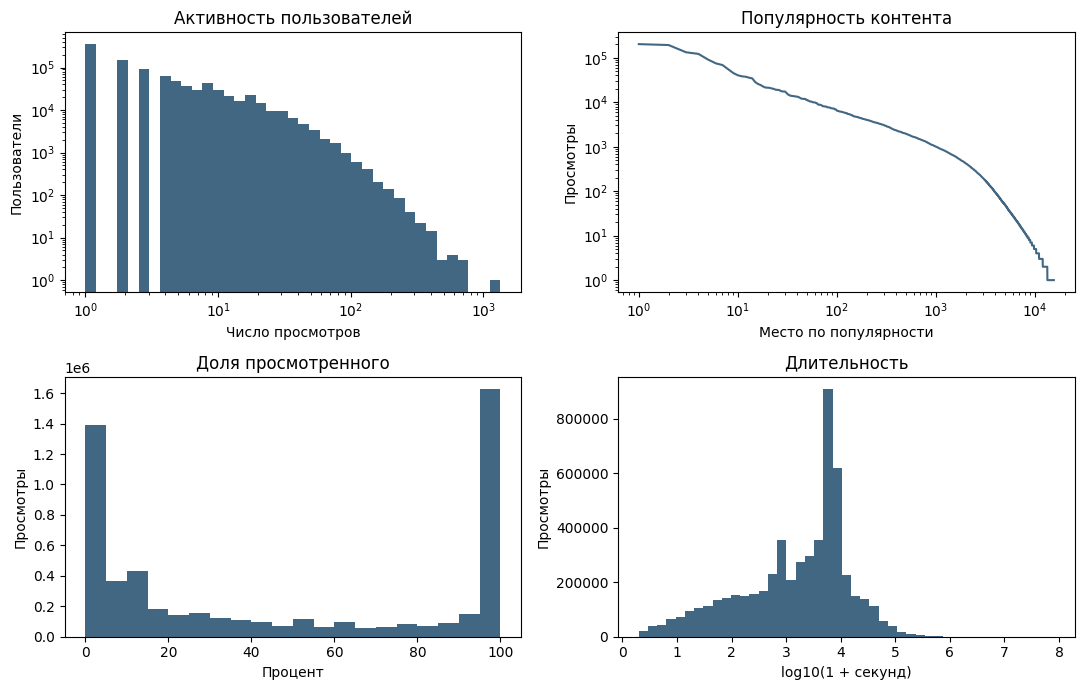

In [31]:
def save_figure(name):
    plt.savefig(FIGURES / f'{name}.png', dpi=160, bbox_inches='tight')
    plt.show()

activity = clean.groupby('user_id').size()
popularity_all = clean.groupby('item_id').size().sort_values(ascending=False)
figure, axes = plt.subplots(2, 2, figsize=(11, 7))
axes[0, 0].hist(activity, bins=np.geomspace(1, activity.max() + 1, 40), color='#426783')
axes[0, 0].set(xscale='log', yscale='log', title='Активность пользователей', xlabel='Число просмотров', ylabel='Пользователи')
axes[0, 1].plot(np.arange(1, len(popularity_all) + 1), popularity_all.to_numpy(), color='#426783')
axes[0, 1].set(xscale='log', yscale='log', title='Популярность контента', xlabel='Место по популярности', ylabel='Просмотры')
axes[1, 0].hist(clean['watched_pct'], bins=20, color='#426783')
axes[1, 0].set(title='Доля просмотренного', xlabel='Процент', ylabel='Просмотры')
axes[1, 1].hist(np.log10(1 + clean['total_dur']), bins=45, color='#426783')
axes[1, 1].set(title='Длительность', xlabel='log10(1 + секунд)', ylabel='Просмотры')
figure.tight_layout()
save_figure('eda')

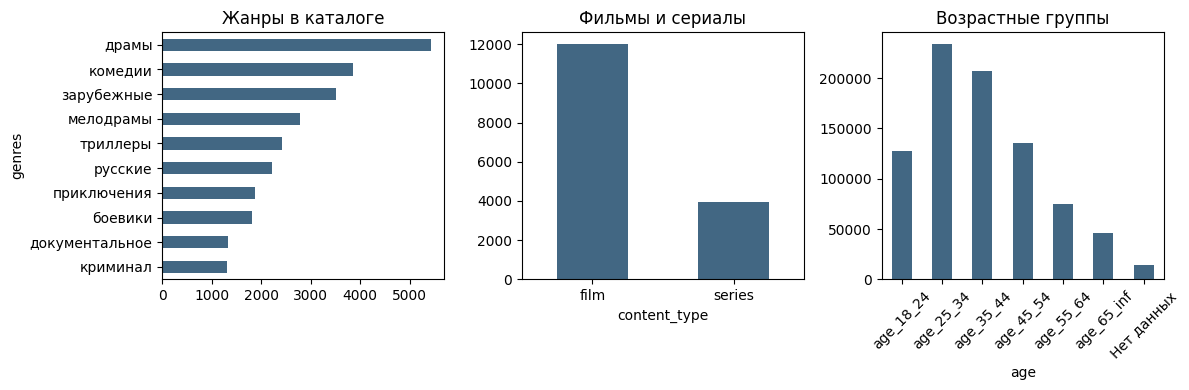

Разреженность: **99.964%**. На 1% самых популярных объектов приходится **45.6%** просмотров. Медиана истории: **2**. 

In [32]:
genre_counts = (items['genres'].dropna().str.split(',').explode().str.strip().value_counts())
figure, axes = plt.subplots(1, 3, figsize=(12, 4))
genre_counts.head(10).sort_values().plot.barh(ax=axes[0], color='#426783', title='Жанры в каталоге')
items['content_type'].value_counts().plot.bar(ax=axes[1], color='#426783', rot=0, title='Фильмы и сериалы')
users['age'].fillna('Нет данных').value_counts().sort_index().plot.bar(
    ax=axes[2], color='#426783', rot=45, title='Возрастные группы')
figure.tight_layout()
save_figure('metadata')
head_share = popularity_all.head(max(1, int(len(popularity_all) * .01))).sum() / len(clean)
display(Markdown(f'Разреженность: **{summary["sparsity"]:.3%}**. На 1% самых популярных объектов '
                 f'приходится **{head_share:.1%}** просмотров. Медиана истории: **{activity.median():.0f}**. '))

## 3 Разбиение по времени

In [33]:
end_date = clean['last_watch_dt'].max().normalize() + pd.Timedelta(days=1)
test_start = end_date - pd.Timedelta(days=7)
val_start = test_start - pd.Timedelta(days=7)
train_all = clean[clean['last_watch_dt'] < val_start]
val_all = clean[clean['last_watch_dt'].between(val_start, test_start, inclusive='left')]
test_all = clean[clean['last_watch_dt'] >= test_start]
catalog_counts = train_all.loc[train_all['positive'], 'item_id'].value_counts()
catalog = np.sort(catalog_counts.head(MAX_ITEMS).index.to_numpy())
train_catalog = train_all[train_all['item_id'].isin(catalog)]
active_counts = train_catalog[train_catalog['positive']].groupby('user_id').size()
eligible = np.sort(active_counts[active_counts >= 5].index.to_numpy())
rng = np.random.default_rng(SEED)
cohort = np.sort(rng.choice(eligible, size=min(MAX_USERS, len(eligible)), replace=False))
user_index = pd.Index(cohort)
item_index = pd.Index(catalog)
train = train_all[train_all['user_id'].isin(cohort)]
validation = val_all[val_all['user_id'].isin(cohort)]
test = test_all[test_all['user_id'].isin(cohort)]
trainval = pd.concat([train, validation], ignore_index=True)

In [34]:
def interaction_matrix(frame, positives_only=True):
    selected = frame[frame['positive']] if positives_only else frame
    row_ids = user_index.get_indexer(selected['user_id'])
    column_ids = item_index.get_indexer(selected['item_id'])
    keep = (row_ids >= 0) & (column_ids >= 0)
    matrix = sparse.csr_matrix((np.ones(keep.sum(), dtype=np.float32),
                                (row_ids[keep], column_ids[keep])),
                               shape=(len(cohort), len(catalog)))
    matrix.sum_duplicates()
    matrix.data[:] = 1
    return matrix

train_matrix = interaction_matrix(train)
train_seen = interaction_matrix(train, positives_only=False)
final_matrix = interaction_matrix(trainval)
final_seen = interaction_matrix(trainval, positives_only=False)
assert train_all['last_watch_dt'].max() < val_all['last_watch_dt'].min()
assert val_all['last_watch_dt'].max() < test_all['last_watch_dt'].min()
assert train_matrix.min() >= 0 and np.unique(train_matrix.data).tolist() == [1.0]

,Часть,Начало,Конец,Просмотры,Пользователи,Положительные
0,Train,2021-03-13,2021-08-08,626520,30000,351991
1,Validation,2021-08-09,2021-08-15,32719,9392,14811
2,Test,2021-08-16,2021-08-22,29576,8810,13220


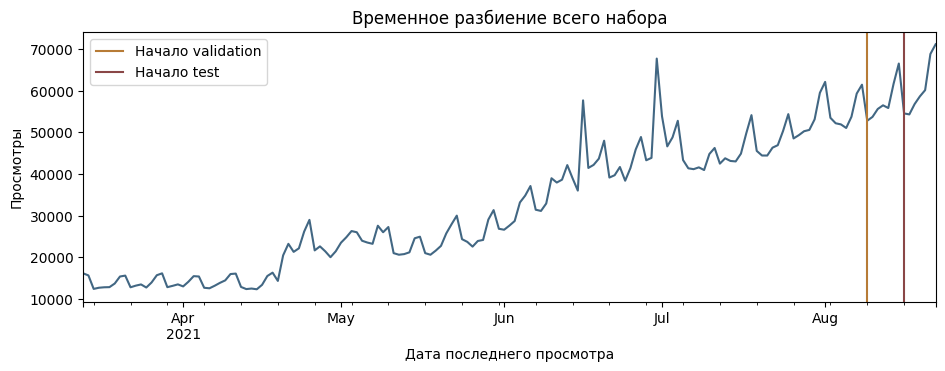

In [35]:
split_table = pd.DataFrame([
    {'Часть': name, 'Начало': str(frame['last_watch_dt'].min().date()),
     'Конец': str(frame['last_watch_dt'].max().date()), 'Просмотры': len(frame),
     'Пользователи': frame['user_id'].nunique(), 'Положительные': int(frame['positive'].sum())}
    for name, frame in [('Train', train), ('Validation', validation), ('Test', test)]])
display(split_table)
figure, axis = plt.subplots(figsize=(11, 3.5))
clean.groupby('last_watch_dt').size().plot(ax=axis, color='#426783')
axis.axvline(val_start, color='#b77b36', label='Начало validation')
axis.axvline(test_start, color='#8a4747', label='Начало test')
axis.set(xlabel='Дата последнего просмотра', ylabel='Просмотры', title='Временное разбиение всего набора')
axis.legend()
save_figure('temporal')

In [36]:
def ground_truth(frame, history):
    relevant = frame[frame['positive']].copy()
    earlier_pairs = pd.MultiIndex.from_frame(history[['user_id', 'item_id']])
    future_pairs = pd.MultiIndex.from_frame(relevant[['user_id', 'item_id']])
    relevant = relevant[~future_pairs.isin(earlier_pairs)]
    grouped = relevant.groupby('user_id')['item_id'].agg(set)
    return {int(user_index.get_loc(user_id)): values for user_id, values in grouped.items()}

val_truth = ground_truth(validation, train)
test_truth = ground_truth(test, trainval)
before_test_all = pd.concat([train_all, val_all], ignore_index=True)
cold_user_mask = ~test_all['user_id'].isin(before_test_all['user_id'])
new_item_mask = ~test_all['item_id'].isin(before_test_all['item_id'])
cold_stats = {
    'test_cold_users_all': int(test_all.loc[cold_user_mask, 'user_id'].nunique()),
    'test_new_items_all': int(test_all.loc[new_item_mask, 'item_id'].nunique()),
    'test_cold_user_interactions_all': int(cold_user_mask.sum()),
    'test_new_item_interactions_all': int(new_item_mask.sum()),
    'test_total_users_all': int(test_all['user_id'].nunique()),
    'test_total_items_all': int(test_all['item_id'].nunique()),
    'test_total_interactions_all': len(test_all),
    'test_users': len(test_truth), 'validation_users': len(val_truth),
    'test_target_catalog_coverage': float(np.mean([
        len(values.intersection(set(catalog))) / len(values) for values in test_truth.values()]))
}
display(pd.Series(cold_stats, name='Значение').to_frame())

,Значение
test_cold_users_all,56108.000000
test_new_items_all,129.000000
test_cold_user_interactions_all,117684.000000
test_new_item_interactions_all,12114.000000
test_total_users_all,167347.000000
test_total_items_all,7105.000000
test_total_interactions_all,424435.000000
test_users,5612.000000
validation_users,6080.000000
test_target_catalog_coverage,0.897375


In [37]:
def oracle_ceiling(truth):
    catalog_set = set(catalog)
    discounts = 1 / np.log2(np.arange(2, TOP_K + 2))
    values = []
    for targets in truth.values():
        reachable = min(TOP_K, len(targets & catalog_set))
        ideal = discounts[:min(TOP_K, len(targets))].sum()
        values.append([reachable / len(targets), discounts[:reachable].sum() / ideal])
    return dict(zip(['recall', 'ndcg'], np.mean(values, axis=0)))

ceilings = {'validation': oracle_ceiling(val_truth), 'test': oracle_ceiling(test_truth)}
display(pd.DataFrame(ceilings).T.rename(columns={'recall': 'Предел Recall@10', 'ndcg': 'Предел NDCG@10'}))

,Предел Recall@10,Предел NDCG@10
validation,0.924924,0.937773
test,0.894113,0.909987


## 4 Модели
MostPop, ItemKNN, EASE, ALS

In [38]:
def fit_itemknn(matrix, neighbors):
    gram = (matrix.T @ matrix).toarray().astype(np.float64)
    norms = np.sqrt(np.diag(gram))
    denominator = norms[:, None] * norms[None, :]
    similarities = np.divide(gram, denominator, out=np.zeros_like(gram), where=denominator > 0)
    np.fill_diagonal(similarities, 0)
    keep = np.argsort(-similarities, axis=0, kind='stable')[:neighbors]
    weights = np.zeros_like(similarities, dtype=np.float32)
    columns = np.broadcast_to(np.arange(matrix.shape[1]), keep.shape)
    weights[keep, columns] = similarities[keep, columns]
    return sparse.csr_matrix(weights)

In [39]:
def fit_ease(matrix, regularization):
    gram = (matrix.T @ matrix).toarray().astype(np.float64)
    gram.flat[::gram.shape[0] + 1] += regularization
    inverse = np.linalg.inv(gram)
    weights = -inverse / np.diag(inverse)[None, :]
    np.fill_diagonal(weights, 0)
    return weights.astype(np.float32)

In [40]:
def als_update(matrix, fixed, regularization, alpha):
    identity = np.eye(fixed.shape[1])
    base = fixed.T @ fixed + regularization * identity
    updated = np.zeros((matrix.shape[0], fixed.shape[1]), dtype=np.float64)
    for row_number in range(matrix.shape[0]):
        columns = matrix.indices[matrix.indptr[row_number]:matrix.indptr[row_number + 1]]
        history_factors = fixed[columns]
        system = base + alpha * (history_factors.T @ history_factors)
        target = (1 + alpha) * history_factors.sum(axis=0)
        updated[row_number] = np.linalg.solve(system, target)
    return updated

In [41]:
def fit_als(matrix, regularization, factors=32, alpha=20, iterations=8):
    generator = np.random.default_rng(SEED)
    item_factors = generator.normal(0, .01, (matrix.shape[1], factors))
    transposed = matrix.T.tocsr()
    for epoch in range(iterations):
        user_factors = als_update(matrix, item_factors, regularization, alpha)
        item_factors = als_update(transposed, user_factors, regularization, alpha)
    user_factors = als_update(matrix, item_factors, regularization, alpha)
    return {'user_factors': user_factors, 'item_factors': item_factors,
            'regularization': regularization, 'alpha': alpha, 'factors': factors,
            'iterations': iterations}

def fit_model(name, matrix, parameter):
    started = perf_counter()
    if name == 'MostPop':
        model = np.asarray(matrix.sum(axis=0)).ravel()
    elif name == 'ItemKNN':
        model = fit_itemknn(matrix, parameter)
    elif name == 'EASE':
        model = fit_ease(matrix, parameter)
    else:
        model = fit_als(matrix, **parameter) if isinstance(parameter, dict) else fit_als(matrix, parameter)
    return model, perf_counter() - started

В обычной X положительный просмотр имеет вес 1. В TimeEASE заменяю его на
Rᵤᵢ = 2^(−ageᵤᵢ/h), чтобы недавняя история влияла сильнее. Здесь h задаётся в днях,
age считается до правой границы обучения; у последнего дня age=1.
EASE обучается на R, оценки равны RB. Для ручной истории без дат все веса равны 1.

In [42]:
def temporal_matrix(frame, boundary, half_life, all_users=False):
    positives = frame[frame['positive']]
    lookup = (pd.Index(np.sort(positives.loc[positives['item_id'].isin(catalog), 'user_id'].unique()))
              if all_users else user_index)
    rows = lookup.get_indexer(positives['user_id'])
    columns = item_index.get_indexer(positives['item_id'])
    keep = (rows >= 0) & (columns >= 0)
    age = ((boundary - positives['last_watch_dt']).dt.total_seconds() / 86400).to_numpy()
    assert age[keep].min() >= 1
    values = np.exp2(-age[keep] / half_life).astype(np.float32)
    return sparse.csr_matrix((values, (rows[keep], columns[keep])), shape=(len(lookup), len(catalog)))

def fit_temporal(frame, boundary, parameter):
    started = perf_counter()
    training = temporal_matrix(frame, boundary, parameter['half_life'], parameter.get('all_users', False))
    history = temporal_matrix(frame, boundary, parameter['half_life'])
    weights = fit_ease(training, parameter['regularization'])
    return {'weights': weights, 'history_matrix': history,
            'training_users': training.shape[0], **parameter}, perf_counter() - started

## 5 Метрики
Coverage показывает долю каталога, встретившуюся в выдачах.
Novelty считаю в битах как среднее −log₂((nᵢ+1)/(U+2)). Для всех моделей использую
одну бинарную матрицу когорты: train при валидации, train + validation при тесте.
U=30000, nᵢ число положительных зрителей объекта. Сглаживание Beta(1,1) позволяет
учесть объекты без положительных просмотров. У MostPop novelty тоже может быть выше нуля.

Для ILD берется среднее расстояние Жаккара между жанрами пар рекомендаций:
1 − |Gᵢ∩Gⱼ|/|Gᵢ∪Gⱼ|. Пары без известных жанров пропускаю.
В выбранном каталоге жанры есть у всех объектов, поэтому учитываются все 45 пар списка.

In [43]:
metadata = items.drop_duplicates('item_id').set_index('item_id')
genre_sets = [set(str(metadata.loc[item_id, 'genres']).split(', '))
              if pd.notna(metadata.loc[item_id, 'genres']) else set() for item_id in catalog]
genre_distances = np.zeros((len(catalog), len(catalog)), dtype=np.float32)
for left in range(len(catalog)):
    for right in range(left + 1, len(catalog)):
        union = genre_sets[left] | genre_sets[right]
        distance = 1 - len(genre_sets[left] & genre_sets[right]) / len(union) if union else np.nan
        if not genre_sets[left] or not genre_sets[right]:
            distance = np.nan
        genre_distances[left, right] = genre_distances[right, left] = distance

In [44]:
def ranking_metrics(recommended_ids, relevant_ids):
    if len(recommended_ids) == 0 or len(relevant_ids) == 0:
        raise ValueError('Нужны непустая выдача и положительные цели')
    if len(set(recommended_ids)) != len(recommended_ids):
        raise ValueError('В выдаче не должно быть дублей')
    hits = np.array([item_id in relevant_ids for item_id in recommended_ids], dtype=float)
    positions = np.arange(1, len(hits) + 1)
    precision = hits.sum() / len(hits)
    recall = hits.sum() / len(relevant_ids)
    ideal = (1 / np.log2(positions[:min(len(hits), len(relevant_ids))] + 1)).sum()
    ndcg = (hits / np.log2(positions + 1)).sum() / ideal
    average_precision = (hits * hits.cumsum() / positions).sum() / len(relevant_ids)
    return precision, recall, ndcg, average_precision

assert np.allclose(ranking_metrics([1, 2, 3], {1, 3}),
                   [2/3, 1, (1 + .5)/(1 + 1/np.log2(3)), (1 + 2/3)/2])
assert ranking_metrics([1, 2, 3], {4}) == (0, 0, 0, 0)
assert np.isclose(ranking_metrics([1, 2, 3], set(range(1, 9)))[3], 3/8)

In [45]:
def score_batch(name, model, matrix, row_ids):
    if name == 'MostPop':
        return np.broadcast_to(model, (len(row_ids), len(catalog))).copy()
    if name in TEMPORAL_NAMES:
        return np.asarray(model['history_matrix'][row_ids] @ model['weights'])
    if name == 'ALS':
        return model['user_factors'][row_ids] @ model['item_factors'].T
    scores = matrix[row_ids] @ model
    return scores.toarray() if sparse.issparse(scores) else np.asarray(scores)

def top_recommendations(name, model, matrix, seen, row_ids, top_k=TOP_K):
    if name == RANKER_NAME:
        return ranker_top_recommendations(model, row_ids, top_k)
    scores = score_batch(name, model, matrix, row_ids)
    watched_rows, watched_columns = seen[row_ids].nonzero()
    scores[watched_rows, watched_columns] = -np.inf
    assert np.isfinite(scores).sum(axis=1).min() >= top_k
    return np.argsort(-scores, axis=1, kind='stable')[:, :top_k]

In [46]:
def evaluate(name, model, matrix, seen, truth):
    if not truth:
        raise ValueError('Нет пользователей с будущими положительными целями')
    row_ids = np.array(sorted(truth))
    frequencies = np.asarray(matrix.sum(axis=0)).ravel()
    novelty = -np.log2((frequencies + 1) / (matrix.shape[0] + 2))
    rows, ranked = [], []
    pair_left, pair_right = np.triu_indices(TOP_K, k=1)
    for start in range(0, len(row_ids), 256):
        batch_ids = row_ids[start:start + 256]
        batch = top_recommendations(name, model, matrix, seen, batch_ids)
        for user_row, recommendations in zip(batch_ids, batch):
            accuracy = ranking_metrics(catalog[recommendations], truth[int(user_row)])
            distances = genre_distances[recommendations[pair_left], recommendations[pair_right]]
            valid = distances[np.isfinite(distances)]
            ild = float(valid.mean()) if len(valid) else np.nan
            hit_rate = float(bool(set(catalog[recommendations]) & truth[int(user_row)]))
            rows.append([*accuracy, float(novelty[recommendations].mean()), ild, hit_rate])
        ranked.append(batch)
    per_user = np.asarray(rows)
    names = ['precision', 'recall', 'ndcg', 'map', 'novelty', 'ild', 'hitrate']
    metrics = {name: float(column[np.isfinite(column)].mean()) if np.isfinite(column).any() else np.nan
               for name, column in zip(names, per_user.T)}
    metrics['ild_valid_users'] = int(np.isfinite(per_user[:, 5]).sum())
    metrics['coverage'] = len(np.unique(np.concatenate(ranked))) / len(catalog)
    return metrics, per_user, np.concatenate(ranked)

## 6 Подбор параметров и сравнение
Параметры выбираю по NDCG@10 на валидации. Для MostPop, ItemKNN и EASE сравнил
обучение на выбранных пользователях и на всех прошлых пользователях каталога.

In [47]:
als_prior_trials = [
    (32, 20, 1.0, 8, 0.07612121244124102),
    (32, 20, 10.0, 8, 0.07670812517331284),
    (64, 5, 10.0, 20, 0.05752141362276107),
    (64, 5, 100.0, 20, 0.09221738419876765),
    (64, 20, 10.0, 20, 0.07010894228141142),
    (64, 20, 100.0, 20, 0.07837354117394907),
    (64, 80, 10.0, 20, 0.06476630292358848),
    (64, 80, 100.0, 20, 0.07713990532829784),
    (128, 5, 100.0, 20, 0.09435484091846441),
    (16, 5, 100.0, 20, 0.08151981094321828),
    (32, 5, 100.0, 20, 0.08459534030269852),
    (128, 20, 100.0, 20, 0.0793311918303137),
    (128, 80, 100.0, 20, 0.0774678618657322),
    (128, 5, 100.0, 40, 0.09458715532536613),
    (64, 5, 100.0, 40, 0.09262694439417064),
    (32, 5, 100.0, 40, 0.08458527523836419),
]
als_prior_table = pd.DataFrame(als_prior_trials, columns=['factors', 'alpha', 'regularization', 'iterations', 'ndcg'])
display(als_prior_table.round(6))

,factors,alpha,regularization,iterations,ndcg
0,32,20,1.0,8,0.076121
1,32,20,10.0,8,0.076708
2,64,5,10.0,20,0.057521
3,64,5,100.0,20,0.092217
4,64,20,10.0,20,0.070109
5,64,20,100.0,20,0.078374
6,64,80,10.0,20,0.064766
7,64,80,100.0,20,0.077140
8,128,5,100.0,20,0.094355
9,16,5,100.0,20,0.081520


In [48]:
als_selected = {'regularization': 100.0, 'factors': 128, 'alpha': 5, 'iterations': 40}

In [49]:
all_train_matrix = temporal_matrix(train_all, val_start, np.inf, all_users=True)
grid = {'MostPop': [None], 'ItemKNN': [30, 100, 300],
        'EASE': [10, 30, 100, 300, 500, 1000, 3000], 'ALS': [10., als_selected]}
validation_rows, chosen_parameters, chosen_pools = [], {}, {}
for model_name, parameters in grid.items():
    best_validation_ndcg = -1
    pool_options = [False, True] if model_name in {'MostPop', 'ItemKNN', 'EASE'} else [False]
    for all_users in pool_options:
        learning_matrix = all_train_matrix if all_users else train_matrix
        for parameter in parameters:
            model, duration = fit_model(model_name, learning_matrix, parameter)
            values, _, _ = evaluate(model_name, model, train_matrix, train_seen, val_truth)
            validation_rows.append({'model': model_name, 'parameter': parameter,
                'training_pool': 'all_users' if all_users else 'cohort',
                'training_users': learning_matrix.shape[0], 'train_seconds': duration, **values})
            print(model_name, parameter, 'all_users' if all_users else 'cohort',
                  f'NDCG={values["ndcg"]:.4f}', flush=True)
            if values['ndcg'] > best_validation_ndcg:
                best_validation_ndcg = values['ndcg']
                chosen_parameters[model_name] = parameter
                chosen_pools[model_name] = all_users
display(pd.DataFrame(validation_rows).round(4))

MostPop None cohort NDCG=0.0747
MostPop None all_users NDCG=0.0773
ItemKNN 30 cohort NDCG=0.0955
ItemKNN 100 cohort NDCG=0.0988
ItemKNN 300 cohort NDCG=0.1019
ItemKNN 30 all_users NDCG=0.0922
ItemKNN 100 all_users NDCG=0.0960
ItemKNN 300 all_users NDCG=0.0975
EASE 10 cohort NDCG=0.0996
EASE 30 cohort NDCG=0.1031
EASE 100 cohort NDCG=0.1048
EASE 300 cohort NDCG=0.1050
EASE 500 cohort NDCG=0.1053
EASE 1000 cohort NDCG=0.1033
EASE 3000 cohort NDCG=0.1010
EASE 10 all_users NDCG=0.1077
EASE 30 all_users NDCG=0.1081
EASE 100 all_users NDCG=0.1086
EASE 300 all_users NDCG=0.1097
EASE 500 all_users NDCG=0.1097
EASE 1000 all_users NDCG=0.1091
EASE 3000 all_users NDCG=0.1076
ALS 10.0 cohort NDCG=0.0767
ALS {'regularization': 100.0, 'factors': 128, 'alpha': 5, 'iterations': 40} cohort NDCG=0.0946


,model,parameter,training_pool,training_users,train_seconds,precision,recall,ndcg,map,novelty,ild,hitrate,ild_valid_users,coverage
0,MostPop,None,cohort,30000,0.0016,0.0195,0.1083,0.0747,0.0522,3.0973,0.8247,0.1780,6080,0.0093
1,MostPop,None,all_users,513513,0.0083,0.0189,0.1052,0.0773,0.0570,3.1550,0.8608,0.1727,6080,0.0093
2,ItemKNN,30,cohort,30000,0.7855,0.0282,0.1354,0.0955,0.0669,4.8091,0.7220,0.2273,6080,0.6017
3,ItemKNN,100,cohort,30000,0.8082,0.0290,0.1384,0.0988,0.0694,4.6862,0.7154,0.2352,6080,0.5520
4,ItemKNN,300,cohort,30000,0.9278,0.0298,0.1430,0.1019,0.0717,4.5639,0.7217,0.2429,6080,0.4973
5,ItemKNN,30,all_users,513513,1.1304,0.0284,0.1344,0.0922,0.0634,5.0352,0.6994,0.2278,6080,0.5593
6,ItemKNN,100,all_users,513513,1.1817,0.0291,0.1378,0.0960,0.0666,4.9040,0.6914,0.2337,6080,0.5003
7,ItemKNN,300,all_users,513513,1.1849,0.0295,0.1397,0.0975,0.0675,4.7802,0.6945,0.2385,6080,0.4373
8,EASE,10,cohort,30000,3.7627,0.0291,0.1411,0.0996,0.0691,4.9777,0.7845,0.2446,6080,0.5143
9,EASE,30,cohort,30000,3.7672,0.0301,0.1452,0.1031,0.0720,4.8499,0.7807,0.2518,6080,0.4280


In [50]:
time_grid = [(7, 30), (14, 30), (14, 100), (21, 30), (21, 100),
             (30, 30), (30, 100), (30, 300), (60, 100), (60, 300), (90, 100)]
best_time_ndcg = -1
for half_life, regularization in time_grid:
    parameter = {'half_life': half_life, 'regularization': regularization}
    model, duration = fit_temporal(train, val_start, parameter)
    values, _, _ = evaluate(TIME_NAME, model, train_matrix, train_seen, val_truth)
    validation_rows.append({'model': TIME_NAME, 'parameter': parameter,
                            'train_seconds': duration, **values})
    print(TIME_NAME, parameter, f'NDCG={values["ndcg"]:.4f}', flush=True)
    if values['ndcg'] > best_time_ndcg:
        best_time_ndcg = values['ndcg']
        chosen_parameters[TIME_NAME] = parameter
display(pd.DataFrame(validation_rows).sort_values('ndcg', ascending=False).head(12))

TimeEASE {'half_life': 7, 'regularization': 30} NDCG=0.1012
TimeEASE {'half_life': 14, 'regularization': 30} NDCG=0.1120
TimeEASE {'half_life': 14, 'regularization': 100} NDCG=0.1149
TimeEASE {'half_life': 21, 'regularization': 30} NDCG=0.1133
TimeEASE {'half_life': 21, 'regularization': 100} NDCG=0.1171
TimeEASE {'half_life': 30, 'regularization': 30} NDCG=0.1142
TimeEASE {'half_life': 30, 'regularization': 100} NDCG=0.1162
TimeEASE {'half_life': 30, 'regularization': 300} NDCG=0.1146
TimeEASE {'half_life': 60, 'regularization': 100} NDCG=0.1135
TimeEASE {'half_life': 60, 'regularization': 300} NDCG=0.1124
TimeEASE {'half_life': 90, 'regularization': 100} NDCG=0.1119


,model,parameter,training_pool,training_users,train_seconds,precision,recall,ndcg,map,novelty,ild,hitrate,ild_valid_users,coverage
28,TimeEASE,"{'half_life': 21, 'regularization': 100}",NaN,NaN,1.619879,0.034391,0.166748,0.117082,0.082014,4.543264,0.777545,0.284704,6080,0.273000
30,TimeEASE,"{'half_life': 30, 'regularization': 100}",NaN,NaN,1.632731,0.034079,0.165286,0.116248,0.081292,4.518120,0.776289,0.282895,6080,0.264667
26,TimeEASE,"{'half_life': 14, 'regularization': 100}",NaN,NaN,1.726918,0.034227,0.164772,0.114934,0.080043,4.626685,0.776318,0.281908,6080,0.329000
31,TimeEASE,"{'half_life': 30, 'regularization': 300}",NaN,NaN,4.251297,0.033454,0.163583,0.114598,0.080114,4.230950,0.784555,0.278783,6080,0.204333
29,TimeEASE,"{'half_life': 30, 'regularization': 30}",NaN,NaN,1.612617,0.033405,0.161702,0.114231,0.079703,4.840827,0.774743,0.278783,6080,0.359333
32,TimeEASE,"{'half_life': 60, 'regularization': 100}",NaN,NaN,4.175814,0.032993,0.160368,0.113547,0.079613,4.535612,0.774001,0.273520,6080,0.271333
27,TimeEASE,"{'half_life': 21, 'regularization': 30}",NaN,NaN,1.605275,0.033109,0.159869,0.113308,0.079367,4.896159,0.774979,0.275000,6080,0.382000
33,TimeEASE,"{'half_life': 60, 'regularization': 300}",NaN,NaN,4.211698,0.032813,0.158096,0.112385,0.078910,4.255637,0.779067,0.272204,6080,0.204333
25,TimeEASE,"{'half_life': 14, 'regularization': 30}",NaN,NaN,3.803233,0.032944,0.158500,0.111972,0.078309,5.016520,0.773241,0.274013,6080,0.440333
34,TimeEASE,"{'half_life': 90, 'regularization': 100}",NaN,NaN,4.249788,0.032467,0.157595,0.111873,0.078655,4.557030,0.774204,0.267763,6080,0.283000


TimeEASE-All обучается на всех прошлых пользователях с положительными просмотрами
каталога. Сравнение с TimeEASE показывает эффект увеличения обучающей выборки.
Каталог и правила оценки при этом те же.

In [51]:
best_all_ndcg = -1
for regularization in [100, 500, 1000, 3000]:
    parameter = {'half_life': chosen_parameters[TIME_NAME]['half_life'],
                 'regularization': regularization, 'all_users': True}
    model, duration = fit_temporal(train_all, val_start, parameter)
    values, _, _ = evaluate(IMPROVED_NAME, model, train_matrix, train_seen, val_truth)
    validation_rows.append({'model': IMPROVED_NAME, 'parameter': parameter,
                            'train_seconds': duration, **values})
    print(IMPROVED_NAME, parameter, f'NDCG={values["ndcg"]:.4f}', flush=True)
    if values['ndcg'] > best_all_ndcg:
        best_all_ndcg = values['ndcg']
        chosen_parameters[IMPROVED_NAME] = parameter
display(pd.DataFrame(validation_rows).sort_values('ndcg', ascending=False).head(12))

TimeEASE-All {'half_life': 21, 'regularization': 100, 'all_users': True} NDCG=0.1230
TimeEASE-All {'half_life': 21, 'regularization': 500, 'all_users': True} NDCG=0.1213
TimeEASE-All {'half_life': 21, 'regularization': 1000, 'all_users': True} NDCG=0.1192
TimeEASE-All {'half_life': 21, 'regularization': 3000, 'all_users': True} NDCG=0.1141


,model,parameter,training_pool,training_users,train_seconds,precision,recall,ndcg,map,novelty,ild,hitrate,ild_valid_users,coverage
35,TimeEASE-All,"{'half_life': 21, 'regularization': 100, 'all_users': True}",NaN,NaN,5.697087,0.036414,0.176664,0.122951,0.085674,4.781708,0.771894,0.298355,6080,0.342667
36,TimeEASE-All,"{'half_life': 21, 'regularization': 500, 'all_users': True}",NaN,NaN,5.221844,0.035855,0.173449,0.121298,0.084827,4.406314,0.781466,0.294408,6080,0.234000
37,TimeEASE-All,"{'half_life': 21, 'regularization': 1000, 'all_users': True}",NaN,NaN,5.590252,0.035214,0.171184,0.119179,0.083275,4.241834,0.789575,0.290132,6080,0.198667
28,TimeEASE,"{'half_life': 21, 'regularization': 100}",NaN,NaN,1.619879,0.034391,0.166748,0.117082,0.082014,4.543264,0.777545,0.284704,6080,0.273000
30,TimeEASE,"{'half_life': 30, 'regularization': 100}",NaN,NaN,1.632731,0.034079,0.165286,0.116248,0.081292,4.518120,0.776289,0.282895,6080,0.264667
26,TimeEASE,"{'half_life': 14, 'regularization': 100}",NaN,NaN,1.726918,0.034227,0.164772,0.114934,0.080043,4.626685,0.776318,0.281908,6080,0.329000
31,TimeEASE,"{'half_life': 30, 'regularization': 300}",NaN,NaN,4.251297,0.033454,0.163583,0.114598,0.080114,4.230950,0.784555,0.278783,6080,0.204333
29,TimeEASE,"{'half_life': 30, 'regularization': 30}",NaN,NaN,1.612617,0.033405,0.161702,0.114231,0.079703,4.840827,0.774743,0.278783,6080,0.359333
38,TimeEASE-All,"{'half_life': 21, 'regularization': 3000, 'all_users': True}",NaN,NaN,5.795693,0.033602,0.164308,0.114077,0.079714,4.020480,0.805118,0.277632,6080,0.151000
32,TimeEASE,"{'half_life': 60, 'regularization': 100}",NaN,NaN,4.175814,0.032993,0.160368,0.113547,0.079613,4.535612,0.774001,0.273520,6080,0.271333


Для LambdaMART сначала собираю кандидатов: top-200 TimeEASE-All и top-50 популярных
за последние семь дней. Просмотренное и повторы убираю, будущие цели в список не добавляю.
Затем ранжирую кандидатов по 19 признакам, в том числе оценке TimeEASE, популярности
и совпадению жанров с историей.

Первое обучающее окно использует историю до 2 августа и метки за 2-8 августа.
По валидации выбираю параметры, перед тестом обучаю на двух прошлых окнах.
Каждая пара «окно, пользователь» образует отдельную группу ранжирования.

In [52]:
def ranker_item_statistics(source, boundary):
    selected = source[source['item_id'].isin(catalog)]
    positive = selected[selected['positive']]
    def counts(frame):
        return (frame.groupby('item_id')['user_id'].nunique()
                .reindex(catalog, fill_value=0).to_numpy(dtype=np.float32))
    first = selected.groupby('item_id')['last_watch_dt'].min().reindex(catalog)
    last = selected.groupby('item_id')['last_watch_dt'].max().reindex(catalog)
    recent = positive[positive['last_watch_dt'] >= boundary - pd.Timedelta(days=7)]
    month = positive[positive['last_watch_dt'] >= boundary - pd.Timedelta(days=30)]
    return {'pop': counts(positive), 'views': counts(selected), 'pop7': counts(recent),
        'pop30': counts(month),
        'age': (boundary - first).dt.total_seconds().fillna(999999).to_numpy() / 86400,
        'freshness': (boundary - last).dt.total_seconds().fillna(999999).to_numpy() / 86400,
        'mean_pct': selected.groupby('item_id')['watched_pct'].mean().reindex(catalog, fill_value=0).to_numpy()}


def ranker_genre_matrix():
    names = sorted(set().union(*genre_sets))
    lookup = {name: position for position, name in enumerate(names)}
    encoded = np.zeros((len(catalog), len(names)), dtype=np.float32)
    for column, values in enumerate(genre_sets):
        for value in values:
            encoded[column, lookup[value]] = 1
    return encoded

In [53]:
def make_ranker_context(source, boundary, weights, half_life=21):
    source = source[source['last_watch_dt'] < boundary]
    positive = source[source['positive'] & source['item_id'].isin(catalog)]
    recent = positive[positive['last_watch_dt'] >= boundary - pd.Timedelta(days=7)]
    binary = interaction_matrix(source)
    timed = temporal_matrix(source, boundary, half_life)
    encoded = ranker_genre_matrix()
    count = np.asarray(binary.sum(axis=1)).ravel()
    time_count = np.asarray(timed.sum(axis=1)).ravel()
    context = {'boundary': boundary, 'weights': weights, 'binary': binary, 'time': timed,
        'seen': interaction_matrix(source, positives_only=False),
        'genre_matrix': encoded,
        'genre_counts': np.maximum(encoded.sum(axis=1), 1), 'counts': count,
        'time_counts': time_count,
        'genre_profile': np.asarray(binary @ encoded) / np.maximum(count[:, None], 1),
        'time_genre_profile': np.asarray(timed @ encoded) / np.maximum(time_count[:, None], 1),
        'recent_counts': recent.groupby('user_id').size().reindex(cohort, fill_value=0).to_numpy(),
        'statistics': ranker_item_statistics(source, boundary),
        'feature_version': RANKER_FEATURE_VERSION}
    context['seen_counts'] = np.asarray(context['seen'].sum(axis=1)).ravel()
    return context

In [54]:
def ranker_fold(context, label_frame, allow_inner_cold_exclusion=False):
    label_frame = label_frame[label_frame['user_id'].isin(cohort)]
    assert label_frame['last_watch_dt'].min() >= context['boundary']
    source = clean[clean['last_watch_dt'] < context['boundary']]
    truth = ground_truth(label_frame, source)
    rows = np.array(sorted(truth))
    cold_rows = rows[context['counts'][rows] == 0]
    if allow_inner_cold_exclusion:
        rows = rows[context['counts'][rows] > 0]
    features, labels, columns, owners, sizes, candidate_hits = [], [], [], [], [], []
    for start in range(0, len(rows), 128):
        batch_rows = rows[start:start + 128]
        scores = np.asarray(context['time'][batch_rows] @ context['weights'])
        for offset, user_row in enumerate(batch_rows):
            profile = stored_ranker_profile(context, user_row)
            selected, values = ranker_profile_candidates(context, profile,
                scores=scores[offset])
            relevant = truth[int(user_row)]
            hits = np.isin(catalog[selected], list(relevant)).astype(np.uint8)
            features.append(values)
            labels.append(hits)
            columns.append(selected)
            owners.append(np.full(len(selected), user_row, dtype=int))
            sizes.append(len(selected))
            candidate_hits.append(int(hits.sum()))
    return {'features': np.concatenate(features), 'labels': np.concatenate(labels),
        'groups': np.asarray(sizes), 'columns': np.concatenate(columns),
        'owners': np.concatenate(owners), 'rows': rows, 'truth': {int(row): truth[int(row)] for row in rows},
        'query_user_ids': np.asarray(cohort)[rows],
        'excluded_cold_groups': len(cold_rows) if allow_inner_cold_exclusion else 0,
        'candidate_recall_micro': sum(candidate_hits) / sum(len(truth[int(row)]) for row in rows),
        'feature_version': RANKER_FEATURE_VERSION, 'boundary': str(context['boundary'])}


def fit_ranker_folds(folds, n_estimators=100, num_leaves=15):
    assert all(fold['feature_version'] == RANKER_FEATURE_VERSION for fold in folds)
    features = np.concatenate([fold['features'] for fold in folds])
    labels = np.concatenate([fold['labels'] for fold in folds])
    groups = np.concatenate([fold['groups'] for fold in folds])
    assert groups.sum() == len(labels) == len(features)
    ranker = LGBMRanker(objective='lambdarank', n_estimators=n_estimators,
        num_leaves=num_leaves, max_depth=5, min_child_samples=100, learning_rate=.05,
        reg_lambda=10, n_jobs=2, random_state=42, verbosity=-1,
        lambdarank_truncation_level=10, deterministic=True)
    ranker.fit(features, labels, group=groups)
    diagnostics = {'folds': len(folds), 'query_groups': len(groups), 'pairs': len(labels),
        'positive_pairs': int(labels.sum()), 'grouping': 'Отдельная группа для каждой пары fold,user',
        'unique_users': int(len(np.unique(np.concatenate([fold['query_user_ids'] for fold in folds])))),
        'boundaries': [fold['boundary'] for fold in folds], 'feature_version': RANKER_FEATURE_VERSION}
    return ranker.booster_, diagnostics

In [55]:
def ranker_top_recommendations(model, row_ids, top_k=10):
    context = model['context']
    scores = np.asarray(context['time'][row_ids] @ context['weights'])
    ranked = []
    for offset, user_row in enumerate(row_ids):
        profile = stored_ranker_profile(context, user_row)
        columns, features = ranker_profile_candidates(context, profile,
            scores=scores[offset])
        prediction = model['booster'].predict(features)
        ranked.append(columns[np.argsort(-prediction, kind='stable')[:top_k]])
    return np.asarray(ranked)

In [56]:
inner_start = val_start - pd.Timedelta(days=7)
inner_source = clean[clean['last_watch_dt'] < inner_start]
ranker_parameter = chosen_parameters[IMPROVED_NAME]
inner_time, _ = fit_temporal(inner_source, inner_start, ranker_parameter)
inner_context = make_ranker_context(inner_source, inner_start, inner_time['weights'], ranker_parameter['half_life'])
inner_labels = clean[(clean['last_watch_dt'] >= inner_start) & (clean['last_watch_dt'] < val_start)]
inner_fold = ranker_fold(inner_context, inner_labels, allow_inner_cold_exclusion=True)
validation_time, _ = fit_temporal(train_all, val_start, ranker_parameter)
validation_context = make_ranker_context(train_all, val_start, validation_time['weights'], ranker_parameter['half_life'])
validation_labels = clean[(clean['last_watch_dt'] >= val_start) & (clean['last_watch_dt'] < test_start)]
validation_fold = ranker_fold(validation_context, validation_labels)
print('Внутренние группы:', len(inner_fold['groups']), 'исключено холодных:', inner_fold['excluded_cold_groups'])
print('Recall кандидатов validation (micro):', validation_fold['candidate_recall_micro'])

Внутренние группы: 7635 исключено холодных: 219
Recall кандидатов validation (micro): 0.5431098507865776


In [57]:
best_ranker_ndcg = -1
for trees, leaves in [(100, 15), (200, 31)]:
    started = perf_counter()
    booster, diagnostics = fit_ranker_folds([inner_fold], trees, leaves)
    ranker_model = {'booster': booster, 'context': validation_context}
    values, _, _ = evaluate(RANKER_NAME, ranker_model, train_matrix, train_seen, val_truth)
    parameter = {'n_estimators': trees, 'num_leaves': leaves}
    validation_rows.append({'model': RANKER_NAME, 'parameter': parameter,
                            'train_seconds': perf_counter() - started, **values})
    print(RANKER_NAME, parameter, f'NDCG={values["ndcg"]:.6f}', flush=True)
    if values['ndcg'] > best_ranker_ndcg:
        best_ranker_ndcg = values['ndcg']
        chosen_parameters[RANKER_NAME] = parameter
display(pd.DataFrame(validation_rows).sort_values('ndcg', ascending=False).head(10))

LambdaMART {'n_estimators': 100, 'num_leaves': 15} NDCG=0.129335
LambdaMART {'n_estimators': 200, 'num_leaves': 31} NDCG=0.127738


,model,parameter,training_pool,training_users,train_seconds,precision,recall,ndcg,map,novelty,ild,hitrate,ild_valid_users,coverage
39,LambdaMART,"{'n_estimators': 100, 'num_leaves': 15}",NaN,NaN,23.108985,0.038158,0.186747,0.129335,0.090339,5.010346,0.762146,0.312993,6080,0.326333
40,LambdaMART,"{'n_estimators': 200, 'num_leaves': 31}",NaN,NaN,37.647140,0.037599,0.184042,0.127738,0.089302,5.104709,0.753173,0.309704,6080,0.355000
35,TimeEASE-All,"{'half_life': 21, 'regularization': 100, 'all_users': True}",NaN,NaN,5.697087,0.036414,0.176664,0.122951,0.085674,4.781708,0.771894,0.298355,6080,0.342667
36,TimeEASE-All,"{'half_life': 21, 'regularization': 500, 'all_users': True}",NaN,NaN,5.221844,0.035855,0.173449,0.121298,0.084827,4.406314,0.781466,0.294408,6080,0.234000
37,TimeEASE-All,"{'half_life': 21, 'regularization': 1000, 'all_users': True}",NaN,NaN,5.590252,0.035214,0.171184,0.119179,0.083275,4.241834,0.789575,0.290132,6080,0.198667
28,TimeEASE,"{'half_life': 21, 'regularization': 100}",NaN,NaN,1.619879,0.034391,0.166748,0.117082,0.082014,4.543264,0.777545,0.284704,6080,0.273000
30,TimeEASE,"{'half_life': 30, 'regularization': 100}",NaN,NaN,1.632731,0.034079,0.165286,0.116248,0.081292,4.518120,0.776289,0.282895,6080,0.264667
26,TimeEASE,"{'half_life': 14, 'regularization': 100}",NaN,NaN,1.726918,0.034227,0.164772,0.114934,0.080043,4.626685,0.776318,0.281908,6080,0.329000
31,TimeEASE,"{'half_life': 30, 'regularization': 300}",NaN,NaN,4.251297,0.033454,0.163583,0.114598,0.080114,4.230950,0.784555,0.278783,6080,0.204333
29,TimeEASE,"{'half_life': 30, 'regularization': 30}",NaN,NaN,1.612617,0.033405,0.161702,0.114231,0.079703,4.840827,0.774743,0.278783,6080,0.359333


In [58]:
all_final_matrix = temporal_matrix(before_test_all, test_start, np.inf, all_users=True)
all_final_training_users = int(all_final_matrix.shape[0])
models, test_rows, user_metrics, test_rankings = {}, [], {}, {}
for model_name, parameter in chosen_parameters.items():
    if model_name == RANKER_NAME:
        started = perf_counter()
        booster, diagnostics = fit_ranker_folds([inner_fold, validation_fold], **parameter)
        context = make_ranker_context(before_test_all, test_start, models[IMPROVED_NAME]['weights'], chosen_parameters[IMPROVED_NAME]['half_life'])
        models[model_name] = {'booster': booster, 'context': context, 'training_diagnostics': diagnostics}
        duration = perf_counter() - started
    elif model_name in TEMPORAL_NAMES:
        frame = before_test_all if parameter.get('all_users', False) else trainval
        models[model_name], duration = fit_temporal(frame, test_start, parameter)
    else:
        learning_matrix = all_final_matrix if chosen_pools.get(model_name, False) else final_matrix
        models[model_name], duration = fit_model(model_name, learning_matrix, parameter)
    started = perf_counter()
    values, per_user, recommendations = evaluate(
        model_name, models[model_name], final_matrix, final_seen, test_truth)
    test_rows.append({'model': model_name, 'parameter': parameter, 'train_seconds': duration,
                      'evaluation_seconds': perf_counter() - started, **values})
    user_metrics[model_name] = per_user
    test_rankings[model_name] = recommendations
results_table = pd.DataFrame(test_rows).set_index('model')
best_model = max(validation_rows, key=lambda row: row['ndcg'])['model']
display(results_table.round(4))
print('Модель для примеров, выбранная по validation:', best_model)

,parameter,train_seconds,evaluation_seconds,precision,recall,ndcg,map,novelty,ild,hitrate,ild_valid_users,coverage
model,,,,,,,,,,,,
MostPop,None,0.0075,2.0949,0.0190,0.1090,0.0787,0.0589,3.1529,0.8612,0.1700,5612,0.0097
ItemKNN,300,0.8727,2.1879,0.0288,0.1427,0.1028,0.0743,4.5280,0.7169,0.2308,5612,0.4567
EASE,500,4.8408,2.0652,0.0311,0.1552,0.1109,0.0798,4.5741,0.7700,0.2534,5612,0.3183
ALS,"{'regularization': 100.0, 'factors': 128, 'alpha': 5, 'iterations': 40}",424.1414,2.1160,0.0274,0.1362,0.0953,0.0673,4.6093,0.7317,0.2238,5612,0.1130
TimeEASE,"{'half_life': 21, 'regularization': 100}",3.9696,1.8274,0.0322,0.1628,0.1142,0.0813,4.5859,0.7765,0.2644,5612,0.2727
TimeEASE-All,"{'half_life': 21, 'regularization': 100, 'all_users': True}",5.4409,2.0260,0.0346,0.1761,0.1217,0.0863,4.8561,0.7691,0.2826,5612,0.3487
LambdaMART,"{'n_estimators': 100, 'num_leaves': 15}",26.7719,8.6209,0.0359,0.1842,0.1274,0.0906,5.0970,0.7744,0.2956,5612,0.3410


Модель для примеров, выбранная по validation: LambdaMART


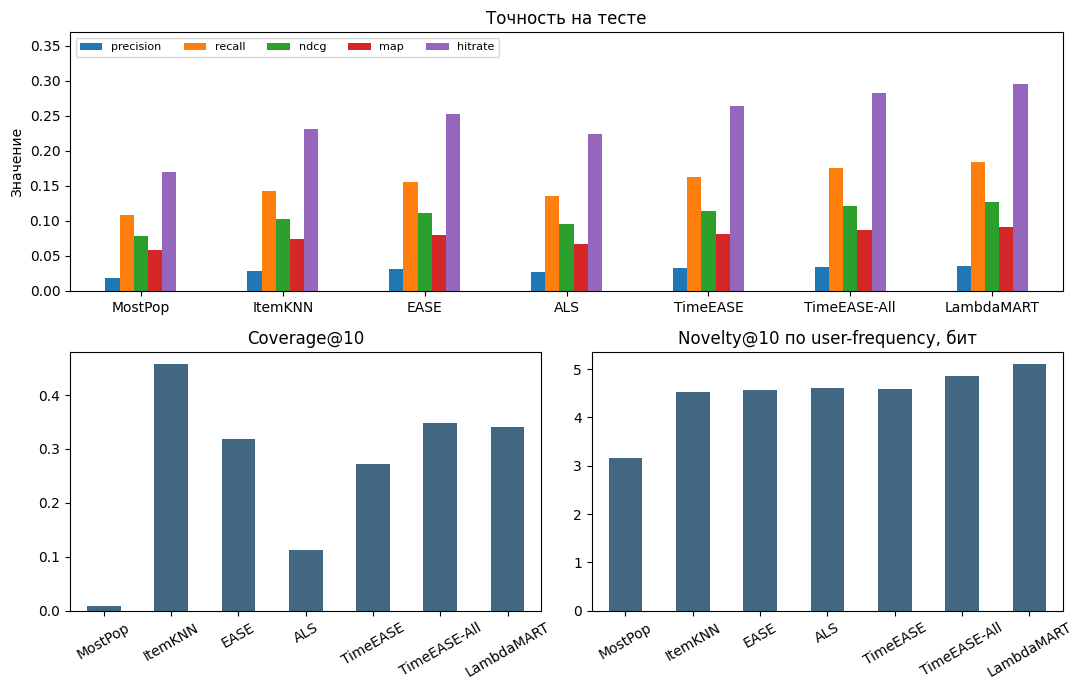

In [59]:
figure = plt.figure(figsize=(11, 7))
layout = figure.add_gridspec(2, 2)
accuracy_axis = figure.add_subplot(layout[0, :])
coverage_axis = figure.add_subplot(layout[1, 0])
novelty_axis = figure.add_subplot(layout[1, 1])
results_table[['precision', 'recall', 'ndcg', 'map', 'hitrate']].plot.bar(ax=accuracy_axis, rot=0)
accuracy_axis.set(title='Точность на тесте', ylabel='Значение', xlabel='')
accuracy_axis.set_ylim(0, results_table['hitrate'].max() * 1.25)
accuracy_axis.legend(loc='upper left', ncol=5, fontsize=8)
results_table['coverage'].plot.bar(ax=coverage_axis, color='#426783', rot=30)
coverage_axis.set(title='Coverage@10', xlabel='')
results_table['novelty'].plot.bar(ax=novelty_axis, color='#426783', rot=30)
novelty_axis.set(title='Novelty@10 по user-frequency, бит', xlabel='')
figure.tight_layout()
save_figure('metrics')

In [60]:
generator = np.random.default_rng(SEED)
bootstrap_rows = []
for model_name in chosen_parameters:
    differences = user_metrics[model_name][:, 2] - user_metrics['MostPop'][:, 2]
    bootstrap = np.array([generator.choice(differences, len(differences), replace=True).mean()
                          for repeat in range(1000)])
    lower, upper = np.quantile(bootstrap, [.025, .975])
    bootstrap_rows.append({'model': model_name, 'delta_ndcg': differences.mean(),
                           'ci_lower': lower, 'ci_upper': upper})
display(pd.DataFrame(bootstrap_rows).round(4))

,model,delta_ndcg,ci_lower,ci_upper
0,MostPop,0.0000,0.0000,0.0000
1,ItemKNN,0.0241,0.0195,0.0287
2,EASE,0.0322,0.0276,0.0369
3,ALS,0.0166,0.0118,0.0212
4,TimeEASE,0.0355,0.0310,0.0401
5,TimeEASE-All,0.0430,0.0382,0.0482
6,LambdaMART,0.0487,0.0441,0.0532


In [61]:
paired_improvement = []
for reference in [IMPROVED_NAME, TIME_NAME, 'EASE', 'ItemKNN', 'MostPop']:
    differences = user_metrics[RANKER_NAME][:, 2] - user_metrics[reference][:, 2]
    samples = np.array([generator.choice(differences, len(differences), replace=True).mean()
                        for repeat in range(2000)])
    lower, upper = np.quantile(samples, [.025, .975])
    paired_improvement.append({'model': RANKER_NAME, 'reference': reference,
        'delta_ndcg': float(differences.mean()), 'ci_lower': float(lower), 'ci_upper': float(upper)})
display(pd.DataFrame(paired_improvement).round(5))

,model,reference,delta_ndcg,ci_lower,ci_upper
0,LambdaMART,TimeEASE-All,0.00574,0.00333,0.00827
1,LambdaMART,TimeEASE,0.01320,0.01001,0.01651
2,LambdaMART,EASE,0.01650,0.01251,0.02036
3,LambdaMART,ItemKNN,0.02459,0.02056,0.02878
4,LambdaMART,MostPop,0.04871,0.04427,0.05353


Для LambdaMART проверил, сколько целей вообще попало в кандидаты и какое качество
возможно при их идеальном порядке. Micro-доля считается по всем целевым парам,
macro как среднее долей пользователей. Цели вне кандидатов из знаменателей не удаляю.

In [62]:
evaluation_rows = np.array(sorted(test_truth))
positive_history_counts = np.asarray(final_matrix.getnnz(axis=1)).ravel()[evaluation_rows]
segment_masks = {
    '5–10': (positive_history_counts >= 5) & (positive_history_counts <= 10),
    '11–20': (positive_history_counts >= 11) & (positive_history_counts <= 20),
    '>20': positive_history_counts > 20}
assert sum(int(mask.sum()) for mask in segment_masks.values()) == len(evaluation_rows)
user_segments = []
for segment, mask in segment_masks.items():
    for model_name, values in user_metrics.items():
        assert len(values) == len(evaluation_rows)
        user_segments.append({'positive_history': segment, 'model': model_name,
            'n_users': int(mask.sum()),
            **{metric: float(values[mask, column].mean()) if mask.any() else None
               for metric, column in [('precision', 0), ('recall', 1), ('ndcg', 2),
                                      ('map', 3), ('hitrate', 6)]}})
display(pd.DataFrame(user_segments).round(4))

,positive_history,model,n_users,precision,recall,ndcg,map,hitrate
0,5–10,MostPop,2389,0.0210,0.1416,0.1015,0.0796,0.1921
1,5–10,ItemKNN,2389,0.0267,0.1704,0.1179,0.0898,0.2340
2,5–10,EASE,2389,0.0278,0.1788,0.1248,0.0956,0.2457
3,5–10,ALS,2389,0.0248,0.1615,0.1101,0.0831,0.2189
4,5–10,TimeEASE,2389,0.0298,0.1918,0.1300,0.0978,0.2625
5,5–10,TimeEASE-All,2389,0.0315,0.2035,0.1359,0.1018,0.2771
6,5–10,LambdaMART,2389,0.0328,0.2144,0.1437,0.1082,0.2901
7,11–20,MostPop,1851,0.0200,0.1057,0.0761,0.0551,0.1761
8,11–20,ItemKNN,1851,0.0308,0.1438,0.1058,0.0758,0.2431
9,11–20,EASE,1851,0.0336,0.1610,0.1152,0.0818,0.2717


In [63]:
diagnostic_fold = ranker_fold(models[RANKER_NAME]['context'], test)
assert np.array_equal(diagnostic_fold['rows'], np.array(sorted(test_truth)))
group_starts = np.r_[0, diagnostic_fold['groups'].cumsum()[:-1]]
candidate_target_counts = np.add.reduceat(diagnostic_fold['labels'], group_starts)
diagnostic_target_counts = np.array([len(diagnostic_fold['truth'][int(user_row)])
    for user_row in diagnostic_fold['rows']])
del diagnostic_fold
oracle_discounts = np.r_[0., (1 / np.log2(np.arange(2, TOP_K + 2))).cumsum()]
catalog_set_for_diagnostics = set(catalog)
candidate_diagnostics = {
    'n_users': len(test_truth),
    'candidate_recall_macro': float((candidate_target_counts / diagnostic_target_counts).mean()),
    'oracle_recall_at_10': float((np.minimum(TOP_K, candidate_target_counts) / diagnostic_target_counts).mean()),
    'oracle_ndcg_at_10': float((oracle_discounts[np.minimum(TOP_K, candidate_target_counts)] /
        oracle_discounts[np.minimum(TOP_K, diagnostic_target_counts)]).mean()),
    'candidate_recall_micro': float(candidate_target_counts.sum() / diagnostic_target_counts.sum()),
    'zero_candidate_target_users': int((candidate_target_counts == 0).sum()),
    'zero_catalog_target_users': sum(not bool(targets & catalog_set_for_diagnostics)
        for targets in test_truth.values())}
display(pd.Series(candidate_diagnostics, name='Значение').to_frame())

,Значение
n_users,5612.000000
candidate_recall_macro,0.535728
oracle_recall_at_10,0.535273
oracle_ndcg_at_10,0.575638
candidate_recall_micro,0.521785
zero_candidate_target_users,1727.000000
zero_catalog_target_users,333.000000


In [64]:
history_lengths = np.diff(final_matrix.indptr)
demo_rows = np.flatnonzero((history_lengths >= 8) & (history_lengths <= 20))
demo_user_ids = cohort[demo_rows[:5]].tolist()
demo_user = int(demo_user_ids[0])
demo_history = trainval[(trainval['user_id'] == demo_user) & trainval['positive']]
explanation_examples = []
for model_name in models:
    user_row = int(user_index.get_loc(demo_user))
    profile = (models[model_name]['history_matrix'][user_row] if model_name in TEMPORAL_NAMES
               else final_matrix[user_row])
    if model_name == RANKER_NAME:
        profile = stored_ranker_profile(models[model_name]['context'], user_row)
    columns = top_recommendations(model_name, models[model_name], final_matrix,
                                   final_seen, [user_row], top_k=5)[0]
    records = [explain_profile(profile, model_name, int(column)) for column in columns]
    explanation_examples.append({'user_id': demo_user, 'model': model_name,
        'history': [{'title': str(metadata.loc[int(item_id), 'title'])}
                    for item_id in demo_history['item_id']], 'recommendations': records})
    display(Markdown(f'**{model_name}**'))
    display(recommendation_table(records[:3]))

**MostPop**

,Место,Название,Оценка,Почему предложено
0,1,Клиника счастья,109468.0,109468 пользователей обучения посмотрели не менее 50%. Оценка по общей популярности.
1,2,Девятаев,77449.0,77449 пользователей обучения посмотрели не менее 50%. Оценка по общей популярности.
2,3,Белый снег,21416.0,21416 пользователей обучения посмотрели не менее 50%. Оценка по общей популярности.


**ItemKNN**

,Место,Название,Оценка,Почему предложено
0,1,Клиника счастья,2.08059,«Хрустальный»: +0.4735; «Секреты семейной жизни»: +0.4077; «Маша»: +0.3417; остальная история: +0.8576
1,2,Девятаев,2.05902,«Хрустальный»: +0.4047; «Гнев человеческий»: +0.3909; «Прабабушка легкого поведения»: +0.3637; остальная история: +0.8998
2,3,Белый снег,1.17722,«Хрустальный»: +0.2441; «Маша»: +0.2082; «Прабабушка легкого поведения»: +0.1929; остальная история: +0.5321


**EASE**

...

,Место,Название,Оценка,Почему предложено
0,1,Клиника счастья,0.40323,«Маша»: +0.1159; «Секреты семейной жизни»: +0.1061; «Хрустальный»: +0.0933; «С днём смерти»: -0.0060; остальная история: +0.0939
1,2,Девятаев,0.19248,«Хрустальный»: +0.0514; «Прабабушка легкого поведения»: +0.0455; «Гнев человеческий»: +0.0449; «Семейка Бигфутов»: -0.0061; остальная история: +0.0568
2,3,Маленький воин,0.10513,«Дружить по-русски»: +0.0314; «Прабабушка легкого поведения»: +0.0229; «Секреты семейной жизни»: +0.0159; «С днём смерти»: -0.0050; остальная история: +0.0398


**TimeEASE-All**

,Место,Название,Оценка,Почему предложено
0,1,Клиника счастья,0.39799,«Секреты семейной жизни»: +0.1356; «Маша»: +0.1324; «Хрустальный»: +0.0640; «Дружить по-русски»: -0.0072; остальная история: +0.0732
1,2,Радиовспышка,0.15053,«Страна чудес Вилли»: +0.0500; «С днём смерти»: +0.0275; «Вирус страха»: +0.0200; «Выстрел в пустоту»: -0.0033; остальная история: +0.0564
2,3,Девятаев,0.14700,«Маша»: +0.0420; «Прабабушка легкого поведения»: +0.0388; «Гнев человеческий»: +0.0340; «Страна чудес Вилли»: -0.0129; остальная история: +0.0450


**LambdaMART**

,Место,Название,Оценка,Почему предложено
0,1,Клиника счастья,1.16072,TreeSHAP: Оценка относительно максимума=1.000: +1.1729; Популярность за 7 дней=8.747: +0.5982; Место в первой ступени=1.000: +0.3620; Сумма временных весов истории=7.083: -0.1613; остальные признаки: +0.3029; база: -1.1139
1,2,Радиовспышка,0.78360,TreeSHAP: Оценка относительно максимума=0.378: +0.9743; Место в первой ступени=2.000: +0.2792; Популярность за 7 дней=7.223: +0.2559; Сумма временных весов истории=7.083: -0.0174; остальные признаки: +0.4055; база: -1.1139
2,3,Райская бухта,0.39661,TreeSHAP: Популярность за 7 дней=6.805: +0.3775; Изменение популярности=1.276: +0.3488; Оценка относительно максимума=0.090: +0.2751; Просмотров за 7 дней=3.000: -0.0066; остальные признаки: +0.5158; база: -1.1139


In [65]:
def recommend(user_id, model_name=None, top_n=5):
    if user_id not in user_index:
        raise ValueError('No such user')
    user_row = int(user_index.get_loc(user_id))
    chosen = model_name or best_model
    if chosen == RANKER_NAME:
        profile = stored_ranker_profile(models[RANKER_NAME]['context'], user_row)
        columns = ranker_top_recommendations(models[RANKER_NAME], [user_row], top_n)[0]
        records = [explain_profile(profile, chosen, int(column)) for column in columns]
        return recommendation_table(records)
    profile = (models[chosen]['history_matrix'][user_row] if chosen in TEMPORAL_NAMES
               else final_matrix[user_row])
    columns = top_recommendations(chosen, models[chosen], final_matrix, final_seen,
                                   [user_row], top_n)[0]
    records = [explain_profile(profile, chosen, int(column)) for column in columns]
    return recommendation_table(records)

demo_ids = [10440, 9728, 12920]
demo_ids = [item_id for item_id in demo_ids if item_id in item_index]
custom_records, custom_model = recommend_profile(demo_ids, best_model, top_n=5)
display(Markdown('Пример своей истории: ' + ', '.join(
    str(metadata.loc[item_id, 'title']) for item_id in demo_ids)))
display(recommendation_table(custom_records))

Пример своей истории: Хрустальный, Гнев человеческий

,Место,Название,Оценка,Почему предложено
0,1,Клиника счастья,2.14220,TreeSHAP: Оценка относительно максимума=1.000: +1.3985; Популярность за 7 дней=8.747: +0.9184; Место в первой ступени=1.000: +0.5789; Оценка с учетом жанров=0.000: -0.1068; остальные признаки: +0.4671; база: -1.1139
1,2,Девятаев,0.94468,TreeSHAP: Оценка относительно максимума=0.734: +1.0722; Популярность за 7 дней=8.142: +0.5040; Место в первой ступени=2.000: +0.3181; Оценка с учетом жанров=0.000: -0.1048; остальные признаки: +0.2691; база: -1.1139
2,3,Прабабушка легкого поведения,0.57465,TreeSHAP: Оценка относительно максимума=0.453: +0.8926; Популярность за 7 дней=7.952: +0.5569; Место в первой ступени=3.000: +0.1888; Оценка с учетом жанров=0.000: -0.0988; остальные признаки: +0.1491; база: -1.1139
3,4,Секреты семейной жизни,0.09914,TreeSHAP: Популярность за 7 дней=7.438: +0.6556; Оценка относительно максимума=0.136: +0.4729; Популярность за 30 дней=8.946: +0.1016; Оценка с учетом жанров=0.000: -0.1174; остальные признаки: +0.1003; база: -1.1139
4,5,Маша,0.01676,TreeSHAP: Оценка относительно максимума=0.138: +0.4811; Популярность за 7 дней=6.870: +0.3188; Оценка с учетом жанров=0.012: +0.1282; Дней с первого наблюдения=120.000: -0.0113; остальные признаки: +0.2139; база: -1.1139


In [66]:
search_titles = metadata.loc[catalog, 'title'].astype(str).str.casefold().str.replace('ё', 'е')
all_genres = sorted(set().union(*genre_sets))
model_box.options = list(models)
model_box.value = best_model
genre_box.options = ['Все', *all_genres]
for control in [search_box, add_button, remove_button, clear_button, example_button, recommend_button, model_box, count_box, type_box, genre_box]:
    control.disabled = False
demo_ready = True
load_example()
display(input_panel)
run_recommendations()
save_demo_model(DEMO_PATH)
print('Подготовленная модель сохранена для следующего быстрого запуска.')

Подготовленная модель сохранена для следующего быстрого запуска.


In [67]:
empty_records, fallback = recommend_profile([], best_model, top_n=5)
assert fallback == 'MostPop' and len(empty_records) == 5
assert all(record['base_component'] == record['score'] for record in empty_records)
example_records, _ = recommend_profile(demo_ids, best_model, top_n=5)
example_ids = [record['item_id'] for record in example_records]
assert len(example_ids) == len(set(example_ids)) == 5
assert not set(example_ids).intersection(demo_ids)
print('Пустая история использует MostPop; выдача не содержит повторов и просмотренного.')


Пустая история использует MostPop; выдача не содержит повторов и просмотренного.


In [68]:
maximum_error = 0.
explanation_checks = 0
for model_name in models:
    for user_row in demo_rows[:5]:
        profile = (models[model_name]['history_matrix'][user_row] if model_name in TEMPORAL_NAMES
                   else final_matrix[user_row])
        if model_name == RANKER_NAME:
            profile = stored_ranker_profile(models[model_name]['context'], user_row)
        columns = top_recommendations(model_name, models[model_name], final_matrix,
                                       final_seen, [int(user_row)], top_k=3)[0]
        for column in columns:
            record = explain_profile(profile, model_name, int(column))
            total = record['base_component'] + sum(part['contribution'] for part in record['all_contributions'])
            maximum_error = max(maximum_error, abs(total - record['score']))
            explanation_checks += 1
for model_name, rankings in test_rankings.items():
    for user_row, columns in zip(sorted(test_truth), rankings):
        assert not set(columns).intersection(final_seen[user_row].indices)
        assert len(set(columns)) == TOP_K
print(f'Проверено {explanation_checks} разложений; максимальная ошибка: {maximum_error:.2e}')

Проверено 105 разложений; максимальная ошибка: 1.83e-07


In [69]:
improved = results_table.loc[best_model]
ordinary = results_table.loc['EASE']
gain = improved['ndcg'] / ordinary['ndcg'] - 1
print(f'{best_model}: NDCG@10 = {improved["ndcg"]:.4f}')
print(f'EASE: NDCG@10 = {ordinary["ndcg"]:.4f}, разница {gain:+.1%}')
for metric in ['coverage', 'novelty', 'ild']:
    leader = results_table[metric].idxmax()
    print(f'{metric}: {leader}, {results_table.loc[leader, metric]:.4f}')


LambdaMART: NDCG@10 = 0.1274
EASE: NDCG@10 = 0.1109, разница +14.9%
coverage: ItemKNN, 0.4567
novelty: LambdaMART, 5.0970
ild: MostPop, 0.8612


## 7. Выводы
Лучший NDCG@10 получился у LambdaMART: 0,1274. Это значение качества порядка,
а не доля правильных рекомендаций. Precision@10 равен 0,0359: в среднем 0,36 известного
будущего попадания на десять рекомендаций. Recall@10 составил 18,4%, HitRate@10 29,6%.
Модель лучше базовых вариантов, но до хорошего восстановления будущих просмотров далеко.

Разницу NDCG проверил парным bootstrap по пользователям: 1000 повторов для сравнения
с MostPop и 2000 для итоговой модели. Интервалы посчитаны отдельно, без поправки
на множественные сравнения. Они описывают этот период при уже обученных моделях.